# Phase 5 — Apriori associations and anomaly screening

## Research objective
Build participant-day transactions, mine association rules with explicit thresholds, test sensitivity and screen unusual observations with coverage-aware methods. Prerequisites: Phase 2 processed daily data and Phase 3 daily/sleep candidate flags. Validated helper and algorithm functions are transferred into separate notebook code cells; each full analysis pipeline is then executed as ordered notebook steps.

Association is not causation. Participants contribute repeated days, and anomaly flags identify candidates for review—not confirmed errors.

In [1]:
from pathlib import Path
import tempfile, json, csv, hashlib, statistics, math, sys
from IPython.display import display, HTML, SVG
def find_project_root(start=Path.cwd()):
    for candidate in (start,*start.parents):
        if (candidate/'data/raw').is_dir() and (candidate/'src').is_dir(): return candidate
    raise RuntimeError('Run this notebook from the FitInsight repository or a child directory')
ROOT=find_project_root()
print('Repository:',ROOT)

Repository: /home/runner/workspace/Fitinsight


## Shared CSV validation, quantiles and proof helpers

In [2]:
"""Shared standard-library helpers for the reproducible Phase 5 analyses."""

from __future__ import annotations

import csv
import hashlib
import json
import math
import platform
from datetime import date
from pathlib import Path
from typing import Any, Iterable


ROOT = find_project_root()
DAILY_PATH = ROOT / "data" / "processed" / "daily_activity_clean.csv"
GENERATED_ROOT = ROOT / "reports" / "generated"
EVIDENCE_ROOT = ROOT / "reports" / "evidence" / "P5"

DAILY_COLUMNS = [
    "id", "activity_date", "total_steps", "total_distance",
    "tracker_distance", "logged_activities_distance",
    "very_active_distance", "moderately_active_distance",
    "light_active_distance", "sedentary_active_distance",
    "very_active_minutes", "fairly_active_minutes", "lightly_active_minutes",
    "sedentary_minutes", "calories", "total_recorded_minutes",
    "is_complete_day", "component_distance_sum", "distance_discrepancy",
]

NUMERIC_COLUMNS = [
    "total_steps", "total_distance", "tracker_distance",
    "logged_activities_distance", "very_active_distance",
    "moderately_active_distance", "light_active_distance",
    "sedentary_active_distance", "very_active_minutes",
    "fairly_active_minutes", "lightly_active_minutes", "sedentary_minutes",
    "calories", "total_recorded_minutes", "component_distance_sum",
]

In [3]:
from __future__ import annotations


def parse_bool(value: str, field: str) -> bool:
    if value == "True":
        return True
    if value == "False":
        return False
    raise ValueError(f"Missing or invalid {field}: {value!r}")

In [4]:
from __future__ import annotations


def parse_number(value: str, field: str) -> float | None:
    if value == "":
        return None
    number = float(value)
    if not math.isfinite(number):
        raise ValueError(f"Non-finite {field}: {value!r}")
    return number

In [5]:
from __future__ import annotations


def load_daily_rows(path: Path | None = None) -> list[dict[str, Any]]:
    """Load and validate the full Phase 2 participant-day table."""
    source = path or DAILY_PATH
    rows: list[dict[str, Any]] = []
    seen: set[tuple[str, date]] = set()
    with source.open("r", encoding="utf-8-sig", newline="") as stream:
        reader = csv.DictReader(stream)
        if reader.fieldnames != DAILY_COLUMNS:
            raise ValueError(
                f"Unexpected daily table schema: {reader.fieldnames!r}"
            )
        for line_number, raw in enumerate(reader, start=2):
            participant = raw["id"]
            if not participant:
                raise ValueError(f"Missing participant key on row {line_number}")
            day = date.fromisoformat(raw["activity_date"])
            key = (participant, day)
            if key in seen:
                raise ValueError(f"Duplicate participant-day key: {key!r}")
            seen.add(key)
            row: dict[str, Any] = {
                "id": participant,
                "activity_date": day,
                "weekday": day.weekday(),
                "is_complete_day": parse_bool(
                    raw["is_complete_day"], "is_complete_day"
                ),
                "distance_discrepancy": parse_bool(
                    raw["distance_discrepancy"], "distance_discrepancy"
                ),
            }
            for field in NUMERIC_COLUMNS:
                row[field] = parse_number(raw[field], field)
                if row[field] is not None and row[field] < 0:
                    raise ValueError(
                        f"Negative {field} on row {line_number}"
                    )
            active = [
                row["very_active_minutes"],
                row["fairly_active_minutes"],
                row["lightly_active_minutes"],
            ]
            row["total_active_minutes"] = (
                sum(active) if all(value is not None for value in active) else None
            )
            recorded = row["total_recorded_minutes"]
            if recorded is None:
                raise ValueError(f"Missing recorded minutes on row {line_number}")
            expected_complete = recorded == 1440
            if row["is_complete_day"] != expected_complete:
                raise ValueError(
                    f"Phase 2 completeness mismatch on row {line_number}"
                )
            minute_components = [
                row["very_active_minutes"],
                row["fairly_active_minutes"],
                row["lightly_active_minutes"],
                row["sedentary_minutes"],
            ]
            if all(value is not None for value in minute_components):
                if not math.isclose(
                    sum(minute_components), recorded, rel_tol=0.0, abs_tol=1e-9
                ):
                    raise ValueError(
                        f"Recorded minute total mismatch on row {line_number}"
                    )
            rows.append(row)
    rows.sort(key=lambda row: (row["activity_date"], row["id"]))
    return rows

In [6]:
from __future__ import annotations


def quantile(values: Iterable[float], probability: float) -> float | None:
    """Linear-interpolated quantile, matching the Phase 3 convention."""
    ordered = sorted(float(value) for value in values)
    if not ordered:
        return None
    if probability < 0 or probability > 1:
        raise ValueError("Quantile probability must be between zero and one")
    position = (len(ordered) - 1) * probability
    low = int(position)
    high = min(low + 1, len(ordered) - 1)
    fraction = position - low
    return ordered[low] + (ordered[high] - ordered[low]) * fraction

In [7]:
from __future__ import annotations


def write_csv(path: Path, fields: list[str], rows: Iterable[dict[str, Any]]) -> int:
    path.parent.mkdir(parents=True, exist_ok=True)
    count = 0
    with path.open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(
            stream,
            fieldnames=fields,
            extrasaction="raise",
            lineterminator="\n",
        )
        writer.writeheader()
        for row in rows:
            serialized = {}
            for field in fields:
                value = row.get(field)
                if isinstance(value, (dict, list, tuple)):
                    value = json.dumps(value, sort_keys=True, separators=(",", ":"))
                serialized[field] = "" if value is None else value
            writer.writerow(serialized)
            count += 1
    return count

In [8]:
from __future__ import annotations


def write_json(path: Path, value: Any) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(
        json.dumps(value, indent=2, sort_keys=True, allow_nan=False) + "\n",
        encoding="utf-8",
    )

In [9]:
from __future__ import annotations


def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

In [10]:
from __future__ import annotations


def proof(task_id: str, **facts: Any) -> None:
    """Print a concise machine-readable proof line after a completed stage."""
    print(
        "FITINSIGHT_PROOF | "
        + task_id
        + " | "
        + json.dumps(facts, sort_keys=True, separators=(",", ":"), allow_nan=False)
    )

In [11]:
from __future__ import annotations


def runtime_info() -> dict[str, Any]:
    return {
        "python": platform.python_version(),
        "implementation": platform.python_implementation(),
        "third_party_packages_used": [],
    }

## Transaction construction, Apriori mining and rule metrics

In [12]:
"""Reproducible participant-day transaction construction and Apriori mining."""

from __future__ import annotations

import itertools
import json
import math
from collections import Counter, defaultdict
from pathlib import Path
from typing import Any, Iterable



DEFAULT_MIN_SUPPORT = 0.05
DEFAULT_MIN_CONFIDENCE = 0.60
DEFAULT_MIN_LIFT = 1.10
DEFAULT_MIN_PARTICIPANTS = 5
DEFAULT_MAX_ITEMSET_SIZE = 3
SUPPORT_SENSITIVITY = (0.03, 0.05, 0.08)
CONFIDENCE_SENSITIVITY = (0.50, 0.60, 0.70)
LIFT_SENSITIVITY = (1.00, 1.10, 1.25)
PARTICIPANT_SENSITIVITY = (3, 5, 10)
EXCLUDED_FAMILY_PAIRS = {
    frozenset(("active_share", "very_active_minutes")),
    frozenset(("active_share", "coverage")),
}

In [13]:
from __future__ import annotations




def minimum_support_count(transaction_count: int, min_support: float) -> int:
    if not 0 < min_support <= 1:
        raise ValueError("min_support must be greater than 0 and at most 1")
    if transaction_count <= 0:
        return 0
    return math.ceil(min_support * transaction_count - 1e-12)

In [14]:
from __future__ import annotations




def _calorie_category(value: float, q1: float, q3: float) -> str:
    if value < q1:
        return "calories:lower"
    if value < q3:
        return "calories:middle"
    return "calories:upper"

In [15]:
from __future__ import annotations




def build_transactions(
    rows: list[dict[str, Any]],
) -> tuple[list[dict[str, Any]], dict[str, str], list[dict[str, str]], dict[str, Any]]:
    """Assign one deterministic, family-exclusive item set per participant-day."""
    if not rows:
        return [], {}, [], {"calories_q1": None, "calories_q3": None}
    calorie_values = [row["calories"] for row in rows if row["calories"] is not None]
    if len(calorie_values) != len(rows):
        raise ValueError("Calories must be present for every transaction")
    q1 = quantile(calorie_values, 0.25)
    q3 = quantile(calorie_values, 0.75)
    if q1 is None or q3 is None:
        raise ValueError("Could not compute calorie quantiles")

    family_by_item: dict[str, str] = {}
    dictionary: list[dict[str, str]] = []

    def register(item: str, family: str, definition: str) -> None:
        family_by_item[item] = family
        dictionary.append(
            {"item": item, "family": family, "definition": definition}
        )

    step_definitions = {
        "steps:zero": "total_steps = 0",
        "steps:lower": "0 < total_steps < 5000",
        "steps:middle": "5000 <= total_steps < 10000",
        "steps:upper": "total_steps >= 10000",
    }
    for item, definition in step_definitions.items():
        register(item, "steps", definition)
    for item, definition in {
        "active_share:lower": "total_active_minutes / total_recorded_minutes < 0.10",
        "active_share:middle": "0.10 <= active share < 0.25",
        "active_share:upper": "active share >= 0.25",
    }.items():
        register(item, "active_share", definition)
    for item, definition in {
        "very_active:zero": "very_active_minutes = 0",
        "very_active:lower": "1 <= very_active_minutes < 30",
        "very_active:upper": "very_active_minutes >= 30",
    }.items():
        register(item, "very_active_minutes", definition)
    for item, definition in {
        "calories:lower": f"calories < Q1 ({q1:.8g})",
        "calories:middle": f"Q1 ({q1:.8g}) <= calories < Q3 ({q3:.8g})",
        "calories:upper": f"calories >= Q3 ({q3:.8g})",
    }.items():
        register(item, "calories", definition)
    for item, definition in {
        "day:weekday": "Monday through Friday",
        "day:weekend": "Saturday or Sunday",
    }.items():
        register(item, "day_type", definition)
    for item, definition in {
        "coverage:complete": "Phase 2 is_complete_day is True (1440 recorded minutes)",
        "coverage:incomplete": "Phase 2 is_complete_day is False",
    }.items():
        register(item, "coverage", definition)

    transactions: list[dict[str, Any]] = []
    for index, row in enumerate(rows, start=1):
        steps = row["total_steps"]
        very_active = row["very_active_minutes"]
        active_total = row["total_active_minutes"]
        recorded = row["total_recorded_minutes"]
        calories = row["calories"]
        if None in (steps, very_active, active_total, recorded, calories):
            raise ValueError(
                f"Missing transaction field for {row['id']} {row['activity_date']}"
            )
        items = []
        if steps == 0:
            items.append("steps:zero")
        elif steps < 5000:
            items.append("steps:lower")
        elif steps < 10000:
            items.append("steps:middle")
        else:
            items.append("steps:upper")
        if recorded <= 0:
            raise ValueError("Active-share transaction requires positive duration")
        active_share = active_total / recorded
        if active_share < 0.10:
            items.append("active_share:lower")
        elif active_share < 0.25:
            items.append("active_share:middle")
        else:
            items.append("active_share:upper")
        if very_active == 0:
            items.append("very_active:zero")
        elif very_active < 30:
            items.append("very_active:lower")
        else:
            items.append("very_active:upper")
        items.append(_calorie_category(calories, q1, q3))
        items.append("day:weekend" if row["weekday"] >= 5 else "day:weekday")
        items.append(
            "coverage:complete" if row["is_complete_day"]
            else "coverage:incomplete"
        )
        if len({family_by_item[item] for item in items}) != len(items):
            raise AssertionError("Transaction contains duplicate item families")
        transactions.append(
            {
                "transaction_id": f"PD-{index:04d}",
                "id": row["id"],
                "date": row["activity_date"].isoformat(),
                "is_complete_day": row["is_complete_day"],
                "items": tuple(sorted(set(items))),
            }
        )
    return (
        transactions,
        family_by_item,
        dictionary,
        {"calories_q1": q1, "calories_q3": q3},
    )

In [16]:
from __future__ import annotations




def _family_compatible(
    items: Iterable[str],
    family_by_item: dict[str, str],
    excluded_family_pairs: set[frozenset[str]] | None = None,
) -> bool:
    families = [family_by_item[item] for item in items]
    family_set = set(families)
    if len(families) != len(family_set):
        return False
    return not any(
        pair.issubset(family_set)
        for pair in (excluded_family_pairs or set())
    )

In [17]:
from __future__ import annotations




def apriori(
    transactions: list[dict[str, Any]],
    family_by_item: dict[str, str],
    min_support: float = DEFAULT_MIN_SUPPORT,
    max_size: int = DEFAULT_MAX_ITEMSET_SIZE,
    excluded_family_pairs: set[frozenset[str]] | None = None,
) -> tuple[dict[tuple[str, ...], dict[str, Any]], dict[str, Any]]:
    """Count frequent itemsets with canonical order, family constraints, and pruning."""
    if max_size < 1:
        raise ValueError("max_size must be at least one")
    n = len(transactions)
    required_count = minimum_support_count(n, min_support)
    normalized = [
        {
            **transaction,
            "_items": frozenset(transaction.get("items", ())),
        }
        for transaction in transactions
    ]
    singleton_counts: Counter[str] = Counter()
    singleton_participants: dict[str, set[str]] = defaultdict(set)
    for transaction in normalized:
        for item in transaction["_items"]:
            if item not in family_by_item:
                raise ValueError(f"Unknown item family for {item!r}")
            singleton_counts[item] += 1
            singleton_participants[item].add(str(transaction["id"]))

    frequent: dict[tuple[str, ...], dict[str, Any]] = {}
    level: set[tuple[str, ...]] = set()
    for item in sorted(singleton_counts):
        count = singleton_counts[item]
        if count >= required_count and n > 0:
            key = (item,)
            level.add(key)
            frequent[key] = {
                "count": count,
                "support": count / n,
                "participants": set(singleton_participants[item]),
            }

    candidates_by_size: dict[str, int] = {"1": len(singleton_counts)}
    frequent_by_size: dict[str, int] = {
        "1": len(level)
    } if level else {}
    subset_pruned = 0
    family_pruned = 0
    dependency_pruned = 0
    for size in range(2, max_size + 1):
        candidates: set[tuple[str, ...]] = set()
        previous = sorted(level)
        previous_set = set(level)
        for left_index, left in enumerate(previous):
            for right in previous[left_index + 1:]:
                merged = tuple(sorted(set(left) | set(right)))
                if len(merged) != size:
                    continue
                if not _family_compatible(merged, family_by_item):
                    family_pruned += 1
                    continue
                if not _family_compatible(
                    merged, family_by_item, excluded_family_pairs
                ):
                    dependency_pruned += 1
                    continue
                if any(
                    tuple(subset) not in previous_set
                    for subset in itertools.combinations(merged, size - 1)
                ):
                    subset_pruned += 1
                    continue
                candidates.add(merged)
        candidates_by_size[str(size)] = len(candidates)
        counts: Counter[tuple[str, ...]] = Counter()
        participants: dict[tuple[str, ...], set[str]] = defaultdict(set)
        for transaction in normalized:
            transaction_items = transaction["_items"]
            for candidate in candidates:
                if set(candidate).issubset(transaction_items):
                    counts[candidate] += 1
                    participants[candidate].add(str(transaction["id"]))
        next_level: set[tuple[str, ...]] = set()
        for candidate in sorted(candidates):
            count = counts[candidate]
            if count >= required_count and n > 0:
                next_level.add(candidate)
                frequent[candidate] = {
                    "count": count,
                    "support": count / n,
                    "participants": participants[candidate],
                }
        if next_level:
            frequent_by_size[str(size)] = len(next_level)
        level = next_level
        if not level:
            break
    return frequent, {
        "transaction_count": n,
        "min_support": min_support,
        "minimum_support_count": required_count,
        "max_itemset_size": max_size,
        "candidate_counts_by_size": candidates_by_size,
        "frequent_itemsets_by_size": frequent_by_size,
        "subset_pruned_candidates": subset_pruned,
        "family_incompatible_candidates_pruned": family_pruned,
        "dependency_related_candidates_pruned": dependency_pruned,
    }

In [18]:
from __future__ import annotations




def _all_nonempty_proper_subsets(
    items: tuple[str, ...],
) -> list[tuple[str, ...]]:
    result = []
    for size in range(1, len(items)):
        result.extend(tuple(subset) for subset in itertools.combinations(items, size))
    return sorted(result)

In [19]:
from __future__ import annotations




def build_rules(
    frequent: dict[tuple[str, ...], dict[str, Any]],
    transaction_count: int,
    min_support: float = DEFAULT_MIN_SUPPORT,
    min_confidence: float = DEFAULT_MIN_CONFIDENCE,
    min_lift: float = DEFAULT_MIN_LIFT,
    min_participants: int = DEFAULT_MIN_PARTICIPANTS,
) -> list[dict[str, Any]]:
    """Return every directed rule from frequent itemsets with explicit eligibility."""
    if not 0 <= min_confidence <= 1:
        raise ValueError("min_confidence must be between zero and one")
    if min_lift < 0 or min_participants < 0:
        raise ValueError("min_lift and min_participants must be nonnegative")
    rule_rows: list[dict[str, Any]] = []
    if transaction_count <= 0:
        return rule_rows
    for joint in sorted(frequent, key=lambda items: (len(items), items)):
        if len(joint) < 2:
            continue
        joint_stats = frequent[joint]
        joint_count = int(joint_stats["count"])
        for antecedent in _all_nonempty_proper_subsets(joint):
            consequent = tuple(item for item in joint if item not in antecedent)
            antecedent_stats = frequent.get(antecedent)
            consequent_stats = frequent.get(consequent)
            if not antecedent_stats or not consequent_stats:
                continue
            antecedent_count = int(antecedent_stats["count"])
            consequent_count = int(consequent_stats["count"])
            if antecedent_count == 0 or consequent_count == 0:
                continue
            support = joint_count / transaction_count
            antecedent_support = antecedent_count / transaction_count
            consequent_support = consequent_count / transaction_count
            confidence = joint_count / antecedent_count
            lift = confidence / consequent_support
            leverage = support - antecedent_support * consequent_support
            participant_count = len(joint_stats["participants"])
            eligible = (
                support + 1e-15 >= min_support
                and confidence + 1e-15 >= min_confidence
                and lift + 1e-15 >= min_lift
                and participant_count >= min_participants
            )
            rule_rows.append(
                {
                    "antecedent": antecedent,
                    "consequent": consequent,
                    "joint": joint,
                    "joint_count": joint_count,
                    "antecedent_count": antecedent_count,
                    "consequent_count": consequent_count,
                    "distinct_participants": participant_count,
                    "support": support,
                    "antecedent_support": antecedent_support,
                    "consequent_support": consequent_support,
                    "confidence": confidence,
                    "lift": lift,
                    "leverage": leverage,
                    "min_support": min_support,
                    "min_confidence": min_confidence,
                    "min_lift": min_lift,
                    "min_participants": min_participants,
                    "eligible": eligible,
                }
            )
    rule_rows.sort(key=lambda row: (row["antecedent"], row["consequent"]))
    return rule_rows

In [20]:
from __future__ import annotations




def participant_balanced_sensitivity(
    transactions: list[dict[str, Any]],
    frequent: dict[tuple[str, ...], dict[str, Any]],
    rules: list[dict[str, Any]],
) -> list[dict[str, Any]]:
    """Average within-person item prevalence and rule confidence without pooling days."""
    by_participant: dict[str, list[frozenset[str]]] = defaultdict(list)
    for transaction in transactions:
        by_participant[str(transaction["id"])].append(
            frozenset(transaction["items"])
        )
    output: list[dict[str, Any]] = []
    for items in sorted(frequent, key=lambda value: (len(value), value)):
        per_person = [
            sum(set(items).issubset(day) for day in days) / len(days)
            for days in by_participant.values()
            if days
        ]
        pooled = frequent[items]["support"]
        output.append(
            {
                "entity_type": "itemset_prevalence",
                "entity": items,
                "pooled_rate": pooled,
                "participant_balanced_rate": (
                    sum(per_person) / len(per_person) if per_person else None
                ),
                "participants_contributing": len(per_person),
                "participant_rate_denominator": len(by_participant),
                "difference_balanced_minus_pooled": (
                    sum(per_person) / len(per_person) - pooled
                    if per_person else None
                ),
            }
        )
    for rule in rules:
        antecedent = set(rule["antecedent"])
        joint = set(rule["joint"])
        confidences = []
        for days in by_participant.values():
            antecedent_count = sum(antecedent.issubset(day) for day in days)
            if antecedent_count:
                joint_count = sum(joint.issubset(day) for day in days)
                confidences.append(joint_count / antecedent_count)
        balanced = sum(confidences) / len(confidences) if confidences else None
        output.append(
            {
                "entity_type": "rule_confidence",
                "entity": f"{rule['antecedent']} -> {rule['consequent']}",
                "pooled_rate": rule["confidence"],
                "participant_balanced_rate": balanced,
                "participants_contributing": len(confidences),
                "participant_rate_denominator": len(by_participant),
                "difference_balanced_minus_pooled": (
                    balanced - rule["confidence"] if balanced is not None else None
                ),
            }
        )
    return output

In [21]:
from __future__ import annotations




def _to_csv_rules(rules: list[dict[str, Any]]) -> list[dict[str, Any]]:
    return [
        {
            "rule_id": f"AR-{index:04d}",
            "antecedent_items": row["antecedent"],
            "consequent_items": row["consequent"],
            "joint_items": row["joint"],
            "joint_transactions": row["joint_count"],
            "distinct_participants": row["distinct_participants"],
            "antecedent_transactions": row["antecedent_count"],
            "consequent_transactions": row["consequent_count"],
            "support": row["support"],
            "antecedent_support": row["antecedent_support"],
            "consequent_support": row["consequent_support"],
            "confidence": row["confidence"],
            "lift": row["lift"],
            "leverage": row["leverage"],
            "min_support": row["min_support"],
            "min_confidence": row["min_confidence"],
            "min_lift": row["min_lift"],
            "min_distinct_participants": row["min_participants"],
            "threshold_eligible": row["eligible"],
        }
        for index, row in enumerate(rules, start=1)
    ]

In [22]:
from __future__ import annotations




def _summary_row(
    scope: str,
    dimension: str,
    parameter_value: float | int,
    support_threshold: float,
    confidence_threshold: float,
    lift_threshold: float,
    participant_threshold: int,
    transactions: list[dict[str, Any]],
    frequent: dict[tuple[str, ...], dict[str, Any]],
    rules: list[dict[str, Any]],
    run_metrics: dict[str, Any],
) -> dict[str, Any]:
    return {
        "scope": scope,
        "sensitivity_dimension": dimension,
        "sensitivity_value": parameter_value,
        "support_threshold": support_threshold,
        "confidence_threshold": confidence_threshold,
        "lift_threshold": lift_threshold,
        "minimum_distinct_participants": participant_threshold,
        "transactions": len(transactions),
        "participants": len({row["id"] for row in transactions}),
        "minimum_support_transactions": run_metrics["minimum_support_count"],
        "frequent_itemsets_by_size": {
            str(size): sum(len(itemset) == size for itemset in frequent)
            for size in range(1, DEFAULT_MAX_ITEMSET_SIZE + 1)
        },
        "rules_examined": len(rules),
        "eligible_rules": sum(bool(rule["eligible"]) for rule in rules),
    }

## Daily and sleep anomaly-screening algorithms

In [23]:
"""Coverage-aware, exploratory anomaly screens for Phase 5."""

from __future__ import annotations

import csv
import json
import math
import statistics
from collections import Counter, defaultdict
from pathlib import Path
from typing import Any



P3_CANDIDATE_PATH = ROOT / 'reports/generated/eda/tables/anomaly_candidates.csv'
P3_METRICS_PATH = ROOT / 'reports/evidence/P3/outlier_screen_metrics.json'
IQR_MULTIPLIER = 1.5
MIN_WITHIN_PERSON_DAYS = 5
MODIFIED_Z_THRESHOLD = 3.5
KNN_K_VALUES = (5, 10)
KNN_TOP_FRACTION = 0.05
KNN_FEATURES = (
    "steps_per_recorded_hour",
    "calories_per_recorded_hour",
    "active_share",
)

In [24]:
from __future__ import annotations




def daily_key(row: dict[str, Any]) -> tuple[str, str]:
    day = row["activity_date"]
    return str(row["id"]), day.isoformat() if hasattr(day, "isoformat") else str(day)

In [25]:
from __future__ import annotations




def active_share(row: dict[str, Any]) -> float | None:
    denominator = row["total_recorded_minutes"]
    numerator = row["total_active_minutes"]
    if denominator is None or numerator is None or denominator <= 0:
        return None
    return numerator / denominator

In [26]:
from __future__ import annotations




def _metric_value(row: dict[str, Any], field: str) -> float | None:
    if field == "active_share":
        return active_share(row)
    value = row.get(field)
    return float(value) if value is not None else None

In [27]:
from __future__ import annotations




def load_phase3_candidate_flags(
    rows: list[dict[str, Any]],
    candidate_path: Path | None = None,
    metrics_path: Path | None = None,
) -> dict[str, Any]:
    """Reuse, validate, and keep the distinct Phase 3 daily and sleep flags."""
    candidate_file = candidate_path or P3_CANDIDATE_PATH
    metrics_file = metrics_path or P3_METRICS_PATH
    if not candidate_file.is_file() or not metrics_file.is_file():
        raise FileNotFoundError(
            "Phase 3 anomaly outputs are required; run python src/eda_analysis.py first"
        )
    known_daily = {daily_key(row) for row in rows}
    daily_flags: dict[tuple[str, str], list[str]] = {}
    daily_rows: list[dict[str, Any]] = []
    sleep_rows: list[dict[str, Any]] = []
    with candidate_file.open("r", encoding="utf-8-sig", newline="") as stream:
        reader = csv.DictReader(stream)
        required = {"record_type", "id", "date", "log_id", "flags"}
        if not reader.fieldnames or not required.issubset(reader.fieldnames):
            raise ValueError("Unexpected Phase 3 anomaly candidate schema")
        for raw in reader:
            if raw["record_type"] == "participant_day":
                key = (raw["id"], raw["date"])
                if key not in known_daily:
                    raise ValueError(f"Phase 3 candidate is absent from daily data: {key}")
                if key in daily_flags:
                    raise ValueError(f"Duplicate Phase 3 daily candidate: {key}")
                flags = [flag.strip() for flag in raw["flags"].split(";") if flag.strip()]
                if not flags:
                    raise ValueError(f"Phase 3 daily candidate has no reason: {key}")
                daily_flags[key] = flags
                daily_rows.append(dict(raw))
            elif raw["record_type"] == "sleep_episode":
                sleep_rows.append(dict(raw))
            else:
                raise ValueError(f"Unknown Phase 3 record grain: {raw['record_type']!r}")
    metrics = json.loads(metrics_file.read_text(encoding="utf-8"))
    if len(daily_rows) != metrics.get("daily_candidate_rows"):
        raise ValueError("Phase 3 daily candidate count does not match its evidence JSON")
    if len(sleep_rows) != metrics.get("sleep_episode_candidate_rows"):
        raise ValueError("Phase 3 sleep candidate count does not match its evidence JSON")
    expected_daily_flags = Counter(metrics.get("daily_flag_counts", {}))
    observed_daily_flags = Counter(
        flag for flags in daily_flags.values() for flag in flags
    )
    if expected_daily_flags != observed_daily_flags:
        raise ValueError("Phase 3 daily flag counts do not match its evidence JSON")
    return {
        "daily_flags": daily_flags,
        "daily_rows": daily_rows,
        "sleep_rows": sleep_rows,
        "metrics": metrics,
        "candidate_path": candidate_file,
        "metrics_path": metrics_file,
    }

In [28]:
from __future__ import annotations




def global_iqr_screen(
    rows: list[dict[str, Any]],
) -> tuple[dict[str, dict[str, Any]], dict[tuple[str, str], list[dict[str, Any]]]]:
    """Apply linear-interpolated 1.5×IQR fences to declared daily fields."""
    fields = [
        "total_steps",
        "calories",
        "total_distance",
        "total_active_minutes",
        "sedentary_minutes",
        "total_recorded_minutes",
        "active_share",
    ]
    fences: dict[str, dict[str, Any]] = {}
    flags: dict[tuple[str, str], list[dict[str, Any]]] = defaultdict(list)
    for field in fields:
        values = [
            value for row in rows
            if (value := _metric_value(row, field)) is not None
        ]
        q1 = quantile(values, 0.25)
        q3 = quantile(values, 0.75)
        if q1 is None or q3 is None:
            fences[field] = {
                "q1": None, "q3": None, "iqr": None,
                "lower_fence": None, "upper_fence": None,
                "observed": len(values), "missing": len(rows) - len(values),
                "low_flags": 0, "high_flags": 0, "flagged_rows": 0,
            }
            continue
        spread = q3 - q1
        lower = q1 - IQR_MULTIPLIER * spread
        upper = q3 + IQR_MULTIPLIER * spread
        low_count = 0
        high_count = 0
        for row in rows:
            value = _metric_value(row, field)
            if value is None:
                continue
            tail = "low" if value < lower else "high" if value > upper else None
            if tail:
                low_count += tail == "low"
                high_count += tail == "high"
                flags[daily_key(row)].append(
                    {
                        "field": field,
                        "tail": tail,
                        "value": value,
                        "q1": q1,
                        "q3": q3,
                        "iqr": spread,
                        "lower_fence": lower,
                        "upper_fence": upper,
                    }
                )
        fences[field] = {
            "q1": q1,
            "q3": q3,
            "iqr": spread,
            "lower_fence": lower,
            "upper_fence": upper,
            "observed": len(values),
            "missing": len(rows) - len(values),
            "low_flags": low_count,
            "high_flags": high_count,
            "flagged_rows": low_count + high_count,
        }
    return fences, dict(flags)

In [29]:
from __future__ import annotations




def within_person_robust_screen(
    rows: list[dict[str, Any]],
    min_days: int = MIN_WITHIN_PERSON_DAYS,
    threshold: float = MODIFIED_Z_THRESHOLD,
) -> tuple[list[dict[str, Any]], dict[tuple[str, str], list[dict[str, Any]]], dict[str, Any]]:
    """Use modified MAD scores, with a finite IQR fallback when MAD is zero."""
    fields = ("total_steps", "active_share")
    by_person: dict[str, list[dict[str, Any]]] = defaultdict(list)
    for row in rows:
        by_person[str(row["id"])].append(row)
    output: list[dict[str, Any]] = []
    flagged: dict[tuple[str, str], list[dict[str, Any]]] = defaultdict(list)
    summary = {
        "minimum_days": min_days,
        "threshold_absolute_modified_z": threshold,
        "metrics": {},
        "zero_mad_groups": 0,
        "iqr_fallback_groups": 0,
        "unscalable_groups": 0,
    }
    group_status: Counter[str] = Counter()
    for participant in sorted(by_person):
        participant_rows = by_person[participant]
        for field in fields:
            valid = [
                (row, _metric_value(row, field))
                for row in participant_rows
                if _metric_value(row, field) is not None
            ]
            values = [float(value) for _, value in valid]
            median = quantile(values, 0.5)
            mad = quantile([abs(value - median) for value in values], 0.5) if median is not None else None
            q1 = quantile(values, 0.25)
            q3 = quantile(values, 0.75)
            iqr = q3 - q1 if q1 is not None and q3 is not None else None
            score_method = "MAD"
            scale = None
            if len(values) < min_days:
                score_method = "insufficient_days"
                group_status[score_method] += 1
            elif mad is not None and mad > 0:
                scale = mad / 0.6744897501960817
            elif iqr is not None and iqr > 0:
                scale = iqr / 1.3489795003921634
                score_method = "IQR_fallback_zero_MAD"
                summary["zero_mad_groups"] += 1
                summary["iqr_fallback_groups"] += 1
                group_status[score_method] += 1
            else:
                score_method = "zero_MAD_and_IQR"
                summary["zero_mad_groups"] += 1
                summary["unscalable_groups"] += 1
                group_status[score_method] += 1
            for row, raw_value in valid:
                score = (
                    (float(raw_value) - median) / scale
                    if scale is not None and median is not None
                    else None
                )
                is_flagged = score is not None and abs(score) > threshold
                record = {
                    "participant_id": participant,
                    "date": row["activity_date"].isoformat(),
                    "metric": field,
                    "value": raw_value,
                    "participant_days": len(values),
                    "minimum_days": min_days,
                    "median": median,
                    "mad": mad,
                    "iqr": iqr,
                    "score": score,
                    "score_method": score_method,
                    "threshold": threshold,
                    "flagged": is_flagged,
                    "status": (
                        "scored"
                        if score is not None
                        else "not_scored_zero_robust_scale"
                        if score_method == "zero_MAD_and_IQR"
                        else "insufficient_days"
                    ),
                }
                output.append(record)
                if is_flagged:
                    flagged[daily_key(row)].append(
                        {
                            "metric": field,
                            "score": score,
                            "score_method": score_method,
                            "threshold": threshold,
                        }
                    )
    summary["groups_by_status"] = dict(sorted(group_status.items()))
    for field in fields:
        metric_rows = [row for row in output if row["metric"] == field]
        summary["metrics"][field] = {
            "scored_rows": sum(row["score"] is not None for row in metric_rows),
            "flagged_rows": sum(row["flagged"] for row in metric_rows),
            "participants": len({row["participant_id"] for row in metric_rows}),
        }
    return output, dict(flagged), summary

In [30]:
from __future__ import annotations




def _knn_features(row: dict[str, Any]) -> tuple[float, float, float]:
    recorded = row["total_recorded_minutes"]
    if recorded is None or recorded <= 0:
        raise ValueError("KNN rate features require positive recorded minutes")
    share = active_share(row)
    if share is None:
        raise ValueError("KNN active-share feature is missing")
    return (
        row["total_steps"] * 60.0 / recorded,
        row["calories"] * 60.0 / recorded,
        share,
    )

In [31]:
from __future__ import annotations




def knn_screen(
    rows: list[dict[str, Any]],
    k_values: tuple[int, ...] = KNN_K_VALUES,
    top_fraction: float = KNN_TOP_FRACTION,
) -> tuple[list[dict[str, Any]], dict[tuple[str, int], set[tuple[str, str]]], list[dict[str, Any]]]:
    """Rank standardized participant-days by mean distance to k nearest peers."""
    if not 0 < top_fraction <= 1:
        raise ValueError("top_fraction must be in (0, 1]")
    scopes = [
        ("pooled", rows),
        ("complete_days", [row for row in rows if row["is_complete_day"]]),
        ("incomplete_days", [row for row in rows if not row["is_complete_day"]]),
    ]
    output: list[dict[str, Any]] = []
    candidate_keys: dict[tuple[str, int], set[tuple[str, str]]] = {}
    summaries: list[dict[str, Any]] = []
    for scope, scope_rows in scopes:
        n = len(scope_rows)
        if n == 0:
            continue
        feature_rows = [_knn_features(row) for row in scope_rows]
        means = [
            sum(vector[index] for vector in feature_rows) / n
            for index in range(len(KNN_FEATURES))
        ]
        standard_deviations = [
            math.sqrt(
                sum((vector[index] - means[index]) ** 2 for vector in feature_rows) / n
            )
            for index in range(len(KNN_FEATURES))
        ]
        scaled = [
            tuple(
                (vector[index] - means[index]) / standard_deviations[index]
                if standard_deviations[index] > 0 else 0.0
                for index in range(len(KNN_FEATURES))
            )
            for vector in feature_rows
        ]
        distances: list[list[float]] = []
        for index, vector in enumerate(scaled):
            neighbors = []
            for other_index, other in enumerate(scaled):
                if index == other_index:
                    continue
                distance = math.sqrt(
                    sum((left - right) ** 2 for left, right in zip(vector, other))
                )
                neighbors.append(distance)
            distances.append(sorted(neighbors))
        for requested_k in k_values:
            if requested_k < 1:
                raise ValueError("k must be positive")
            if n < 2:
                continue
            effective_k = min(requested_k, n - 1)
            scores = [
                sum(neighbors[:effective_k]) / effective_k
                for neighbors in distances
            ]
            ranked_indices = sorted(
                range(n),
                key=lambda index: (
                    -scores[index],
                    str(scope_rows[index]["id"]),
                    scope_rows[index]["activity_date"],
                ),
            )
            top_count = max(1, math.ceil(top_fraction * n - 1e-12))
            flagged_indices = set(ranked_indices[:top_count])
            scope_flags = {
                daily_key(scope_rows[index]) for index in flagged_indices
            }
            candidate_keys[(scope, requested_k)] = scope_flags
            threshold_score = scores[ranked_indices[top_count - 1]]
            rank_for_index = {
                row_index: rank
                for rank, row_index in enumerate(ranked_indices, start=1)
            }
            for index, row in enumerate(scope_rows):
                rank = rank_for_index[index]
                output.append(
                    {
                        "scope": scope,
                        "requested_k": requested_k,
                        "effective_k": effective_k,
                        "participant_id": row["id"],
                        "date": row["activity_date"].isoformat(),
                        "neighbor_mean_distance": scores[index],
                        "rank_highest_first": rank,
                        "rank_percentile": (
                            (n - rank) / (n - 1) if n > 1 else 1.0
                        ),
                        "cohort_size": n,
                        "top_fraction": top_fraction,
                        "top_candidate_count": top_count,
                        "cutoff_score": threshold_score,
                        "top_candidate": index in flagged_indices,
                    }
                )
            score_values = scores
            summaries.append(
                {
                    "scope": scope,
                    "requested_k": requested_k,
                    "effective_k": effective_k,
                    "cohort_size": n,
                    "top_fraction": top_fraction,
                    "top_candidate_count": top_count,
                    "score_median": quantile(score_values, 0.5),
                    "score_p90": quantile(score_values, 0.9),
                    "score_p95": quantile(score_values, 0.95),
                    "score_max": max(score_values),
                    "cutoff_score": threshold_score,
                    "feature_names": list(KNN_FEATURES),
                }
            )
    return output, candidate_keys, summaries

In [32]:
from __future__ import annotations




def _distance_screens(
    rows: list[dict[str, Any]],
) -> tuple[set[tuple[str, str]], set[tuple[str, str]], dict[str, Any]]:
    p2_keys = {
        daily_key(row) for row in rows if row["distance_discrepancy"]
    }
    p1_keys = set()
    for row in rows:
        component_sum = row["component_distance_sum"]
        total = row["total_distance"]
        if component_sum is not None and total is not None:
            if abs(component_sum - total) > 0.01:
                p1_keys.add(daily_key(row))
    return p1_keys, p2_keys, {
        "phase1_definition": (
            "|component_distance_sum - total_distance| > 0.01 "
            "(plain absolute-difference screen)"
        ),
        "phase1_candidate_days": len(p1_keys),
        "phase2_definition": (
            "committed Phase 2 distance_discrepancy flag using the existing "
            "NumPy-isclose-equivalent tolerance"
        ),
        "phase2_candidate_days": len(p2_keys),
        "intersection_days": len(p1_keys & p2_keys),
        "phase1_only_days": len(p1_keys - p2_keys),
        "phase2_only_days": len(p2_keys - p1_keys),
        "not_interchangeable": True,
    }

In [33]:
from __future__ import annotations




def _method_sets(
    rows: list[dict[str, Any]],
    p3_flags: dict[tuple[str, str], list[str]],
    global_flags: dict[tuple[str, str], list[dict[str, Any]]],
    within_flags: dict[tuple[str, str], list[dict[str, Any]]],
    knn_flags: dict[tuple[str, int], set[tuple[str, str]]],
    p1_keys: set[tuple[str, str]],
    p2_keys: set[tuple[str, str]],
) -> dict[str, set[tuple[str, str]]]:
    zero_step_flags = {
        daily_key(row)
        for row in rows
        if row["total_steps"] == 0
        and (
            row["calories"] > 0
            or (row["total_active_minutes"] is not None
                and row["total_active_minutes"] > 0)
        )
    }
    complete_k5 = knn_flags.get(("complete_days", 5), set())
    incomplete_k5 = knn_flags.get(("incomplete_days", 5), set())
    complete_k10 = knn_flags.get(("complete_days", 10), set())
    incomplete_k10 = knn_flags.get(("incomplete_days", 10), set())
    return {
        "phase3_daily_candidates": set(p3_flags),
        "global_iqr_any_field": set(global_flags),
        "within_person_robust": set(within_flags),
        "knn_pooled_k5_top_5pct": set(knn_flags.get(("pooled", 5), set())),
        "knn_pooled_k10_top_5pct": set(knn_flags.get(("pooled", 10), set())),
        "knn_stratified_k5_top_5pct": set(complete_k5 | incomplete_k5),
        "knn_stratified_k10_top_5pct": set(complete_k10 | incomplete_k10),
        "zero_steps_with_positive_calories_or_activity": zero_step_flags,
        "phase1_absolute_distance_gt_0_01": p1_keys,
        "phase2_distance_flag": p2_keys,
    }

In [34]:
from __future__ import annotations




def _overlap_tables(
    method_sets: dict[str, set[tuple[str, str]]],
) -> tuple[list[dict[str, Any]], list[dict[str, Any]]]:
    counts = [
        {
            "method": name,
            "candidate_days": len(values),
            "grain": "participant-day",
        }
        for name, values in sorted(method_sets.items())
    ]
    overlaps = []
    names = sorted(method_sets)
    for left_index, left in enumerate(names):
        for right in names[left_index + 1:]:
            a, b = method_sets[left], method_sets[right]
            intersection = a & b
            union = a | b
            overlaps.append(
                {
                    "method_a": left,
                    "method_b": right,
                    "candidate_days_a": len(a),
                    "candidate_days_b": len(b),
                    "intersection_days": len(intersection),
                    "union_days": len(union),
                    "jaccard": len(intersection) / len(union) if union else None,
                }
            )
    return counts, overlaps

In [35]:
from __future__ import annotations




def _candidate_registry(
    rows: list[dict[str, Any]],
    p3_flags: dict[tuple[str, str], list[str]],
    global_flags: dict[tuple[str, str], list[dict[str, Any]]],
    within_flags: dict[tuple[str, str], list[dict[str, Any]]],
    knn_flags: dict[tuple[str, int], set[tuple[str, str]]],
    p1_keys: set[tuple[str, str]],
    p2_keys: set[tuple[str, str]],
) -> list[dict[str, Any]]:
    result = []
    for row in rows:
        key = daily_key(row)
        active = active_share(row)
        p3 = p3_flags.get(key, [])
        global_rows = global_flags.get(key, [])
        within_rows = within_flags.get(key, [])
        flags = []
        if p3:
            flags.append("phase3_candidate")
        if global_rows:
            flags.append("global_iqr")
        if within_rows:
            flags.append("within_person_robust")
        if key in knn_flags.get(("pooled", 5), set()):
            flags.append("knn_pooled_k5")
        if key in knn_flags.get(("pooled", 10), set()):
            flags.append("knn_pooled_k10")
        if key in (
            knn_flags.get(("complete_days", 5), set())
            | knn_flags.get(("incomplete_days", 5), set())
        ):
            flags.append("knn_stratified_k5")
        if key in (
            knn_flags.get(("complete_days", 10), set())
            | knn_flags.get(("incomplete_days", 10), set())
        ):
            flags.append("knn_stratified_k10")
        if key in p1_keys:
            flags.append("phase1_absolute_distance_gt_0_01")
        if key in p2_keys:
            flags.append("phase2_distance_flag")
        if row["total_steps"] == 0 and (
            row["calories"] > 0 or (row["total_active_minutes"] or 0) > 0
        ):
            flags.append("zero_steps_positive_calories_or_activity")
        result.append(
            {
                "participant_id": row["id"],
                "date": row["activity_date"].isoformat(),
                "complete_day": row["is_complete_day"],
                "total_steps": row["total_steps"],
                "calories": row["calories"],
                "total_distance": row["total_distance"],
                "component_distance_sum": row["component_distance_sum"],
                "component_distance_absolute_gap": (
                    abs(row["component_distance_sum"] - row["total_distance"])
                    if row["component_distance_sum"] is not None
                    and row["total_distance"] is not None
                    else None
                ),
                "total_active_minutes": row["total_active_minutes"],
                "total_recorded_minutes": row["total_recorded_minutes"],
                "active_share": active,
                "phase3_flags": p3,
                "global_iqr_flags": [
                    f"{entry['field']}:{entry['tail']}" for entry in global_rows
                ],
                "within_person_flags": [
                    {
                        "metric": entry["metric"],
                        "score": entry["score"],
                        "method": entry["score_method"],
                    }
                    for entry in within_rows
                ],
                "knn_pooled_k5": key in knn_flags.get(("pooled", 5), set()),
                "knn_pooled_k10": key in knn_flags.get(("pooled", 10), set()),
                "knn_stratified_k5": key in (
                    knn_flags.get(("complete_days", 5), set())
                    | knn_flags.get(("incomplete_days", 5), set())
                ),
                "knn_stratified_k10": key in (
                    knn_flags.get(("complete_days", 10), set())
                    | knn_flags.get(("incomplete_days", 10), set())
                ),
                "phase1_absolute_distance_gt_0_01": key in p1_keys,
                "phase2_distance_flag": key in p2_keys,
                "candidate_methods": flags,
                "any_candidate": bool(flags),
            }
        )
    return result

In [36]:
from __future__ import annotations




def _review_cases(
    rows: list[dict[str, Any]],
    registry: list[dict[str, Any]],
    within_rows: list[dict[str, Any]],
    knn_rows: list[dict[str, Any]],
) -> list[dict[str, Any]]:
    row_by_key = {daily_key(row): row for row in rows}
    registry_by_key = {
        (row["participant_id"], row["date"]): row for row in registry
    }
    roles: dict[tuple[str, str], list[str]] = defaultdict(list)

    def add(role: str, key: tuple[str, str] | None) -> None:
        if key is not None and key in row_by_key and role not in roles[key]:
            roles[key].append(role)

    p3_candidates = sorted(
        (key for key, row in registry_by_key.items() if row["phase3_flags"])
    )
    add("Existing Phase 3 participant-day candidate", p3_candidates[0] if p3_candidates else None)
    p1_only = [
        key for key, row in registry_by_key.items()
        if row["phase1_absolute_distance_gt_0_01"] and not row["phase2_distance_flag"]
    ]
    p1_only.sort(
        key=lambda key: -abs(
            row_by_key[key]["component_distance_sum"]
            - row_by_key[key]["total_distance"]
        )
    )
    add("Strict absolute-distance screen only", p1_only[0] if p1_only else None)
    p2_candidates = [
        key for key, row in registry_by_key.items() if row["phase2_distance_flag"]
    ]
    p2_candidates.sort(
        key=lambda key: -abs(
            row_by_key[key]["component_distance_sum"]
            - row_by_key[key]["total_distance"]
        )
    )
    add("Phase 2 distance-flag example", p2_candidates[0] if p2_candidates else None)
    high_steps = [
        row for row in registry
        if any(flag == "total_steps:high" for flag in row["global_iqr_flags"])
    ]
    high_steps.sort(key=lambda row: (-row["total_steps"], row["date"]))
    add(
        "Global upper IQR step screen",
        (high_steps[0]["participant_id"], high_steps[0]["date"])
        if high_steps else None,
    )
    within_candidates = [row for row in within_rows if row["flagged"]]
    within_candidates.sort(key=lambda row: -abs(row["score"]))
    add(
        "Within-participant robust score",
        (within_candidates[0]["participant_id"], within_candidates[0]["date"])
        if within_candidates else None,
    )
    pooled_k5 = [
        row for row in knn_rows
        if row["scope"] == "pooled"
        and row["requested_k"] == 5 and row["top_candidate"]
    ]
    pooled_k5.sort(key=lambda row: -row["neighbor_mean_distance"])
    add(
        "Pooled kNN top-five-percent score",
        (pooled_k5[0]["participant_id"], pooled_k5[0]["date"])
        if pooled_k5 else None,
    )
    incomplete = [
        row for row in rows
        if not row["is_complete_day"] and row["total_recorded_minutes"] > 0
    ]
    incomplete.sort(key=lambda row: (row["total_recorded_minutes"], row["id"], row["activity_date"]))
    add(
        "Shortest positive-duration incomplete record",
        daily_key(incomplete[0]) if incomplete else None,
    )
    latest_date = max((row["activity_date"] for row in rows), default=None)
    boundary = [
        row for row in rows if row["activity_date"] == latest_date
    ]
    if boundary:
        boundary.sort(key=lambda row: (row["id"], row["activity_date"]))
        add("Last observed date retained in primary screen", daily_key(boundary[0]))

    output = []
    for index, key in enumerate(sorted(roles), start=1):
        source = row_by_key[key]
        reg = registry_by_key[key]
        output.append(
            {
                "case_id": f"CASE-{index:03d}",
                "participant_id": source["id"],
                "date": source["activity_date"].isoformat(),
                "selection_reasons": roles[key],
                "total_steps": source["total_steps"],
                "calories": source["calories"],
                "total_distance": source["total_distance"],
                "component_distance_sum": source["component_distance_sum"],
                "component_distance_absolute_gap": (
                    abs(source["component_distance_sum"] - source["total_distance"])
                    if source["component_distance_sum"] is not None
                    and source["total_distance"] is not None else None
                ),
                "total_active_minutes": source["total_active_minutes"],
                "total_recorded_minutes": source["total_recorded_minutes"],
                "active_share": active_share(source),
                "complete_day": source["is_complete_day"],
                "phase3_flags": reg["phase3_flags"],
                "global_iqr_flags": reg["global_iqr_flags"],
                "within_person_flags": reg["within_person_flags"],
                "candidate_methods": reg["candidate_methods"],
                "phase1_absolute_distance_gt_0_01": reg[
                    "phase1_absolute_distance_gt_0_01"
                ],
                "phase2_distance_flag": reg["phase2_distance_flag"],
                "interpretation": (
                    "Retained observed record selected for focused review; "
                    "a screen is not a confirmed error or an inferred cause."
                ),
            }
        )
    return output

In [37]:
from __future__ import annotations




def _date_boundary_rows(
    rows: list[dict[str, Any]],
    p3_flags: dict[tuple[str, str], list[str]],
    primary_sets: dict[str, set[tuple[str, str]]],
    boundary_date: str,
) -> tuple[list[dict[str, Any]], dict[str, Any]]:
    without_boundary = [
        row for row in rows if row["activity_date"].isoformat() != boundary_date
    ]
    without_keys = {daily_key(row) for row in without_boundary}
    p3_without = {key for key in p3_flags if key in without_keys}
    global_fences, global_flags = global_iqr_screen(without_boundary)
    within_rows, within_flags, within_summary = within_person_robust_screen(
        without_boundary
    )
    knn_rows, knn_flags, knn_summary = knn_screen(without_boundary)
    p1_without, p2_without, _ = _distance_screens(without_boundary)
    recomputed_sets = _method_sets(
        without_boundary,
        {key: p3_flags[key] for key in p3_without},
        global_flags,
        within_flags,
        knn_flags,
        p1_without,
        p2_without,
    )
    rows_out = []
    for method, primary in sorted(primary_sets.items()):
        sensitivity = recomputed_sets.get(method, set())
        rows_out.append(
            {
                "method": method,
                "primary_candidate_days": len(primary),
                "excluding_last_date_candidate_days": len(sensitivity),
                "change_after_excluding_last_date": len(sensitivity) - len(primary),
                "boundary_date": boundary_date,
                "primary_includes_boundary": True,
                "sensitivity_recomputed": method not in ("phase3_daily_candidates",),
                "note": (
                    "Phase 3 candidate flags are reused from their original run "
                    "and filtered only; other screens are recalculated."
                ),
            }
        )
    return rows_out, {
        "boundary_date": boundary_date,
        "primary_rows": len(rows),
        "sensitivity_rows": len(without_boundary),
        "primary_retains_boundary": True,
        "global_iqr_refit": True,
        "within_person_refit": True,
        "knn_refit": True,
        "phase3_flags_reused_not_refit": True,
        "global_iqr_fences_excluding_boundary": global_fences,
        "within_person_excluding_boundary": within_summary,
        "knn_excluding_boundary": knn_summary,
    }

## Accessible SVG drawing helpers

In [38]:
"""Small accessible SVG chart helpers for Phase 5; no plotting packages required."""

from __future__ import annotations

import html
from pathlib import Path
from typing import Any

PALETTE = {
    "blue": "#2563eb",
    "teal": "#0f766e",
    "orange": "#d97706",
    "red": "#b91c1c",
    "purple": "#7c3aed",
    "gray": "#64748b",
    "light": "#cbd5e1",
    "green": "#15803d",
}

In [39]:
from __future__ import annotations


def _esc(value: Any) -> str:
    return html.escape(str(value), quote=True)

In [40]:
from __future__ import annotations


def _wrapped(text: str, width: int = 135) -> list[str]:
    words = text.split()
    lines = []
    current = ""
    for word in words:
        candidate = word if not current else current + " " + word
        if len(candidate) > width and current:
            lines.append(current)
            current = word
        else:
            current = candidate
    if current:
        lines.append(current)
    return lines

In [41]:
from __future__ import annotations


def write_horizontal_bars(
    path: Path,
    *,
    title: str,
    description: str,
    subtitle: str,
    labels: list[str],
    series: list[dict[str, Any]],
    axis_label: str,
    interpretation: str,
    limitation: str,
    x_max: float | None = None,
) -> dict[str, Any]:
    width = 1100
    left, right = 235, 1055
    plot_width = right - left
    row_height = 27
    plot_top = 160
    plot_bottom = plot_top + row_height * max(1, len(labels))
    footer_lines = _wrapped("Interpretation: " + interpretation, 145)
    limit_lines = _wrapped("Limitation: " + limitation, 145)
    height = plot_bottom + 78 + 18 * (len(footer_lines) + len(limit_lines))
    values = [
        float(value)
        for entry in series
        for value in entry.get("values", [])
    ]
    maximum = x_max if x_max is not None else max(values, default=1.0)
    if maximum <= 0:
        maximum = 1.0
    legend = "  ".join(str(entry["name"]) for entry in series)
    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" '
        f'viewBox="0 0 {width} {height}" role="img" aria-labelledby="title desc">',
        f"<title id=\"title\">{_esc(title)}</title>",
        f"<desc id=\"desc\">{_esc(description)}</desc>",
        '<rect width="100%" height="100%" fill="#ffffff"/>',
        f'<text x="34" y="42" font-family="sans-serif" font-size="24" font-weight="700">{_esc(title)}</text>',
        f'<text x="34" y="70" font-family="sans-serif" font-size="13" fill="#334155">{_esc(subtitle)}</text>',
    ]
    legend_x = left
    for entry in series:
        color = entry.get("color", PALETTE["blue"])
        parts.append(
            f'<rect x="{legend_x}" y="91" width="13" height="13" fill="{_esc(color)}"/>'
        )
        parts.append(
            f'<text x="{legend_x + 19}" y="102" font-family="sans-serif" font-size="12">{_esc(entry["name"])}</text>'
        )
        legend_x += max(140, 8 * len(str(entry["name"])) + 48)
    for tick in range(5):
        fraction = tick / 4
        x = left + plot_width * fraction
        value = maximum * fraction
        parts.append(
            f'<line x1="{x:.2f}" y1="{plot_top - 5}" x2="{x:.2f}" y2="{plot_bottom}" stroke="#e2e8f0"/>'
        )
        parts.append(
            f'<text x="{x:.2f}" y="{plot_bottom + 19}" text-anchor="middle" '
            f'font-family="sans-serif" font-size="11" fill="#475569">{value:.3g}</text>'
        )
    for index, label in enumerate(labels):
        y = plot_top + index * row_height + row_height / 2
        parts.append(
            f'<text x="{left - 12}" y="{y + 4:.2f}" text-anchor="end" '
            f'font-family="sans-serif" font-size="11" fill="#334155">{_esc(label)}</text>'
        )
        series_count = max(1, len(series))
        bar_height = min(10, (row_height - 4) / series_count)
        for series_index, entry in enumerate(series):
            values_for_series = entry.get("values", [])
            value = float(values_for_series[index]) if index < len(values_for_series) else 0.0
            bar_y = (
                plot_top + index * row_height + 2
                + series_index * (bar_height + 2)
            )
            bar_width = max(0.0, min(plot_width, value / maximum * plot_width))
            parts.append(
                f'<rect x="{left}" y="{bar_y:.2f}" width="{bar_width:.2f}" '
                f'height="{bar_height:.2f}" fill="{_esc(entry.get("color", PALETTE["blue"]))}"/>'
            )
    parts.append(
        f'<text x="{left + plot_width / 2}" y="{plot_bottom + 45}" text-anchor="middle" '
        f'font-family="sans-serif" font-size="12" fill="#334155">{_esc(axis_label)}</text>'
    )
    footer_y = plot_bottom + 70
    for label_text, lines in (
        ("Interpretation:", footer_lines),
        ("Limitation:", limit_lines),
    ):
        for line in lines:
            parts.append(
                f'<text x="34" y="{footer_y}" font-family="sans-serif" font-size="12" fill="#334155">{_esc(line)}</text>'
            )
            footer_y += 18
    parts.append("</svg>")
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text("\n".join(parts) + "\n", encoding="utf-8")
    return {
        "title": title,
        "description": description,
        "subtitle": subtitle,
        "axis_label": axis_label,
        "legend": legend,
        "interpretation": interpretation,
        "limitation": limitation,
        "path": str(path),
    }

In [42]:
from __future__ import annotations


def write_scatter(
    path: Path,
    *,
    title: str,
    description: str,
    subtitle: str,
    points: list[dict[str, Any]],
    x_label: str,
    y_label: str,
    x_max: float,
    interpretation: str,
    limitation: str,
) -> dict[str, Any]:
    width, height = 1040, 650
    left, right, top, bottom = 100, 995, 150, 475
    plot_width, plot_height = right - left, bottom - top
    footer_lines = _wrapped("Interpretation: " + interpretation, 145)
    limit_lines = _wrapped("Limitation: " + limitation, 145)
    parts = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" '
        f'viewBox="0 0 {width} {height}" role="img" aria-labelledby="title desc">',
        f"<title id=\"title\">{_esc(title)}</title>",
        f"<desc id=\"desc\">{_esc(description)}</desc>",
        '<rect width="100%" height="100%" fill="#ffffff"/>',
        f'<text x="34" y="42" font-family="sans-serif" font-size="24" font-weight="700">{_esc(title)}</text>',
        f'<text x="34" y="70" font-family="sans-serif" font-size="13" fill="#334155">{_esc(subtitle)}</text>',
        f'<rect x="{left}" y="105" width="13" height="13" fill="{PALETTE["green"]}"/>',
        f'<text x="{left + 19}" y="116" font-family="sans-serif" font-size="12">Meets all prespecified thresholds</text>',
        f'<rect x="{left + 270}" y="105" width="13" height="13" fill="{PALETTE["gray"]}"/>',
        f'<text x="{left + 289}" y="116" font-family="sans-serif" font-size="12">Does not meet all thresholds</text>',
    ]
    x_max = max(x_max, 0.01)
    for tick in range(5):
        fraction = tick / 4
        x = left + plot_width * fraction
        y = bottom - plot_height * fraction
        parts.append(
            f'<line x1="{x:.2f}" y1="{top}" x2="{x:.2f}" y2="{bottom}" stroke="#e2e8f0"/>'
        )
        parts.append(
            f'<line x1="{left}" y1="{y:.2f}" x2="{right}" y2="{y:.2f}" stroke="#e2e8f0"/>'
        )
        parts.append(
            f'<text x="{x:.2f}" y="{bottom + 20}" text-anchor="middle" font-family="sans-serif" '
            f'font-size="11" fill="#475569">{fraction * x_max:.1%}</text>'
        )
        parts.append(
            f'<text x="{left - 10}" y="{y + 4:.2f}" text-anchor="end" font-family="sans-serif" '
            f'font-size="11" fill="#475569">{fraction:.0%}</text>'
        )
    for point in points:
        x_value = max(0.0, min(x_max, float(point["x"])))
        y_value = max(0.0, min(1.0, float(point["y"])))
        x = left + x_value / x_max * plot_width
        y = bottom - y_value * plot_height
        color = PALETTE["green"] if point["eligible"] else PALETTE["gray"]
        parts.append(
            f'<circle cx="{x:.2f}" cy="{y:.2f}" r="4.5" fill="{color}" fill-opacity="0.75"/>'
        )
    parts.extend(
        [
            f'<text x="{left + plot_width / 2}" y="{bottom + 45}" text-anchor="middle" '
            f'font-family="sans-serif" font-size="12">{_esc(x_label)}</text>',
            f'<text x="24" y="{top + plot_height / 2}" text-anchor="middle" '
            f'transform="rotate(-90 24 {top + plot_height / 2})" font-family="sans-serif" '
            f'font-size="12">{_esc(y_label)}</text>',
        ]
    )
    footer_y = 548
    for lines in (footer_lines, limit_lines):
        for line in lines:
            parts.append(
                f'<text x="34" y="{footer_y}" font-family="sans-serif" font-size="12" fill="#334155">{_esc(line)}</text>'
            )
            footer_y += 18
    parts.append("</svg>")
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text("\n".join(parts) + "\n", encoding="utf-8")
    return {
        "title": title,
        "description": description,
        "subtitle": subtitle,
        "x_label": x_label,
        "y_label": y_label,
        "legend": "Eligible / not eligible under all prespecified thresholds",
        "interpretation": interpretation,
        "limitation": limitation,
        "path": str(path),
    }

## Execute the association analysis by stage

In [43]:
scratch=Path(tempfile.mkdtemp(prefix='_notebook_p5_',dir=ROOT))
phase5_evidence=scratch/'reports/evidence/P5'
assoc_out=scratch/'reports/generated/associations'
anomaly_out=scratch/'reports/generated/anomalies'
daily_input=ROOT/'data/processed/daily_activity_clean.csv'
phase3_candidates=ROOT/'reports/generated/eda/tables/anomaly_candidates.csv'
phase3_metrics=ROOT/'reports/evidence/P3/outlier_screen_metrics.json'
input_path=daily_input
generated_dir=assoc_out
evidence_dir=phase5_evidence


## Build and validate participant-day transactions

In [44]:
rows = load_daily_rows(input_path or DAILY_PATH)

In [45]:
proof(
        "P5-ASSOC-LOAD",
        rows=len(rows),
        participants=len({row["id"] for row in rows}),
        complete_days=sum(row["is_complete_day"] for row in rows),
        incomplete_days=sum(not row["is_complete_day"] for row in rows),
        positive_recorded_minutes=sum(row["total_recorded_minutes"] > 0 for row in rows),
        duplicate_keys=0,
    )

FITINSIGHT_PROOF | P5-ASSOC-LOAD | {"complete_days":233,"duplicate_keys":0,"incomplete_days":224,"participants":35,"positive_recorded_minutes":457,"rows":457}


In [46]:
transactions, family_by_item, item_dictionary, cutpoints = build_transactions(rows)

In [47]:
for row in transactions:
        if len(row["items"]) != len(set(row["items"])):
            raise AssertionError("Duplicate item within transaction")
        if len({family_by_item[item] for item in row["items"]}) != len(row["items"]):
            raise AssertionError("Multiple categories from one family")

In [48]:
family_counts = Counter(family_by_item[item] for row in transactions for item in row["items"])

In [49]:
proof(
        "P5-ASSOC-BINS",
        families=len(set(family_by_item.values())),
        item_count=len(family_by_item),
        family_assignment_checks=len(transactions),
        calories_q1=cutpoints["calories_q1"],
        calories_q3=cutpoints["calories_q3"],
        step_bins="zero, 1-4999, 5000-9999, 10000+",
        active_share_bins="<0.10, 0.10-<0.25, >=0.25",
    )

FITINSIGHT_PROOF | P5-ASSOC-BINS | {"active_share_bins":"<0.10, 0.10-<0.25, >=0.25","calories_q1":1776.0,"calories_q3":2667.0,"families":6,"family_assignment_checks":457,"item_count":17,"step_bins":"zero, 1-4999, 5000-9999, 10000+"}


In [50]:
proof(
        "P5-ASSOC-TRANSACTIONS",
        transactions=len(transactions),
        participant_count=len({row["id"] for row in transactions}),
        item_occurrences=sum(len(row["items"]) for row in transactions),
        min_items_per_day=min((len(row["items"]) for row in transactions), default=0),
        max_items_per_day=max((len(row["items"]) for row in transactions), default=0),
        family_occurrences=family_counts,
    )

FITINSIGHT_PROOF | P5-ASSOC-TRANSACTIONS | {"family_occurrences":{"active_share":457,"calories":457,"coverage":457,"day_type":457,"steps":457,"very_active_minutes":457},"item_occurrences":2742,"max_items_per_day":6,"min_items_per_day":6,"participant_count":35,"transactions":457}


## Mine frequent itemsets and construct directional rules

In [51]:
baseline_frequent, baseline_run = apriori(
        transactions,
        family_by_item,
        DEFAULT_MIN_SUPPORT,
        DEFAULT_MAX_ITEMSET_SIZE,
        EXCLUDED_FAMILY_PAIRS,
    )

In [52]:
baseline_rules = build_rules(
        baseline_frequent,
        len(transactions),
        DEFAULT_MIN_SUPPORT,
        DEFAULT_MIN_CONFIDENCE,
        DEFAULT_MIN_LIFT,
        DEFAULT_MIN_PARTICIPANTS,
    )

In [53]:
eligible_rules = [rule for rule in baseline_rules if rule["eligible"]]

In [54]:
proof(
        "P5-ASSOC-APRIORI",
        **baseline_run,
        observed_support_denominator=len(transactions),
        itemset_count=len(baseline_frequent),
    )

FITINSIGHT_PROOF | P5-ASSOC-APRIORI | {"candidate_counts_by_size":{"1":17,"2":104,"3":164},"dependency_related_candidates_pruned":100,"family_incompatible_candidates_pruned":135,"frequent_itemsets_by_size":{"1":17,"2":82,"3":116},"itemset_count":215,"max_itemset_size":3,"min_support":0.05,"minimum_support_count":23,"observed_support_denominator":457,"subset_pruned_candidates":84,"transaction_count":457}


In [55]:
proof(
        "P5-ASSOC-RULES",
        rules_examined=len(baseline_rules),
        eligible_rules=len(eligible_rules),
        min_confidence=DEFAULT_MIN_CONFIDENCE,
        min_lift=DEFAULT_MIN_LIFT,
        min_distinct_participants=DEFAULT_MIN_PARTICIPANTS,
        metrics=["support", "confidence", "lift", "leverage"],
        distinct_participant_counts=all(
            rule["distinct_participants"] >= 0 for rule in baseline_rules
        ),
    )

FITINSIGHT_PROOF | P5-ASSOC-RULES | {"distinct_participant_counts":true,"eligible_rules":89,"metrics":["support","confidence","lift","leverage"],"min_confidence":0.6,"min_distinct_participants":5,"min_lift":1.1,"rules_examined":860}


## Measure threshold and participant-balance sensitivity

In [56]:
balanced_rows = participant_balanced_sensitivity(
        transactions, baseline_frequent, baseline_rules
    )

In [57]:
sensitivity_rows = []

In [58]:
complete_transactions = [
        transaction for transaction in transactions if transaction["is_complete_day"]
    ]

In [59]:
complete_frequent, complete_run = apriori(
        complete_transactions,
        family_by_item,
        DEFAULT_MIN_SUPPORT,
        DEFAULT_MAX_ITEMSET_SIZE,
        EXCLUDED_FAMILY_PAIRS,
    )

In [60]:
complete_rules_at_default = build_rules(
        complete_frequent,
        len(complete_transactions),
        DEFAULT_MIN_SUPPORT,
        DEFAULT_MIN_CONFIDENCE,
        DEFAULT_MIN_LIFT,
        DEFAULT_MIN_PARTICIPANTS,
    )

In [61]:
scope_inputs = (
        ("all_days", transactions, baseline_frequent, baseline_run),
        ("complete_days", complete_transactions, complete_frequent, complete_run),
    )

In [62]:
for scope, scoped_transactions, default_frequent, default_run in scope_inputs:
        for threshold in SUPPORT_SENSITIVITY:
            frequent, run_metrics = apriori(
                scoped_transactions,
                family_by_item,
                threshold,
                DEFAULT_MAX_ITEMSET_SIZE,
                EXCLUDED_FAMILY_PAIRS,
            )
            rules = build_rules(
                frequent,
                len(scoped_transactions),
                threshold,
                DEFAULT_MIN_CONFIDENCE,
                DEFAULT_MIN_LIFT,
                DEFAULT_MIN_PARTICIPANTS,
            )
            sensitivity_rows.append(
                _summary_row(
                    scope,
                    "minimum_support",
                    threshold,
                    threshold,
                    DEFAULT_MIN_CONFIDENCE,
                    DEFAULT_MIN_LIFT,
                    DEFAULT_MIN_PARTICIPANTS,
                    scoped_transactions,
                    frequent,
                    rules,
                    run_metrics,
                )
            )
        for threshold in CONFIDENCE_SENSITIVITY:
            rules = build_rules(
                default_frequent,
                len(scoped_transactions),
                DEFAULT_MIN_SUPPORT,
                threshold,
                DEFAULT_MIN_LIFT,
                DEFAULT_MIN_PARTICIPANTS,
            )
            sensitivity_rows.append(
                _summary_row(
                    scope,
                    "minimum_confidence",
                    threshold,
                    DEFAULT_MIN_SUPPORT,
                    threshold,
                    DEFAULT_MIN_LIFT,
                    DEFAULT_MIN_PARTICIPANTS,
                    scoped_transactions,
                    default_frequent,
                    rules,
                    default_run,
                )
            )
        for threshold in LIFT_SENSITIVITY:
            rules = build_rules(
                default_frequent,
                len(scoped_transactions),
                DEFAULT_MIN_SUPPORT,
                DEFAULT_MIN_CONFIDENCE,
                threshold,
                DEFAULT_MIN_PARTICIPANTS,
            )
            sensitivity_rows.append(
                _summary_row(
                    scope,
                    "minimum_lift",
                    threshold,
                    DEFAULT_MIN_SUPPORT,
                    DEFAULT_MIN_CONFIDENCE,
                    threshold,
                    DEFAULT_MIN_PARTICIPANTS,
                    scoped_transactions,
                    default_frequent,
                    rules,
                    default_run,
                )
            )
        for threshold in PARTICIPANT_SENSITIVITY:
            rules = build_rules(
                default_frequent,
                len(scoped_transactions),
                DEFAULT_MIN_SUPPORT,
                DEFAULT_MIN_CONFIDENCE,
                DEFAULT_MIN_LIFT,
                threshold,
            )
            sensitivity_rows.append(
                _summary_row(
                    scope,
                    "minimum_participants",
                    threshold,
                    DEFAULT_MIN_SUPPORT,
                    DEFAULT_MIN_CONFIDENCE,
                    DEFAULT_MIN_LIFT,
                    threshold,
                    scoped_transactions,
                    default_frequent,
                    rules,
                    default_run,
                )
            )

In [63]:
proof(
        "P5-ASSOC-SENSITIVITY",
        participant_balanced_rows=len(balanced_rows),
        support_thresholds=list(SUPPORT_SENSITIVITY),
        confidence_thresholds=list(CONFIDENCE_SENSITIVITY),
        lift_thresholds=list(LIFT_SENSITIVITY),
        participant_thresholds=list(PARTICIPANT_SENSITIVITY),
        complete_day_transactions=len(complete_transactions),
        complete_day_participants=len(
            {row["id"] for row in complete_transactions}
        ),
        all_days_eligible_rules=sum(rule["eligible"] for rule in baseline_rules),
        complete_days_eligible_rules=sum(
            rule["eligible"] for rule in complete_rules_at_default
        ),
    )

FITINSIGHT_PROOF | P5-ASSOC-SENSITIVITY | {"all_days_eligible_rules":89,"complete_day_participants":28,"complete_day_transactions":233,"complete_days_eligible_rules":108,"confidence_thresholds":[0.5,0.6,0.7],"lift_thresholds":[1.0,1.1,1.25],"participant_balanced_rows":1075,"participant_thresholds":[3,5,10],"support_thresholds":[0.03,0.05,0.08]}


## Write transaction, itemset and rule outputs

In [64]:
out = generated_dir or GENERATED_ROOT / "associations"

In [65]:
evidence = evidence_dir or EVIDENCE_ROOT

In [66]:
out.mkdir(parents=True, exist_ok=True)

In [67]:
evidence.mkdir(parents=True, exist_ok=True)

In [68]:
transaction_rows = [
        {
            "transaction_id": row["transaction_id"],
            "participant_id": row["id"],
            "date": row["date"],
            "complete_day": row["is_complete_day"],
            "items": row["items"],
        }
        for row in transactions
    ]

In [69]:
flattened = [
        {
            "transaction_id": row["transaction_id"],
            "participant_id": row["id"],
            "date": row["date"],
            "item": item,
            "family": family_by_item[item],
        }
        for row in transactions
        for item in row["items"]
    ]

In [70]:
itemset_rows = [
        {
            "items": items,
            "itemset_size": len(items),
            "transactions": stats["count"],
            "distinct_participants": len(stats["participants"]),
            "support": stats["support"],
            "minimum_support": DEFAULT_MIN_SUPPORT,
            "minimum_support_transactions": baseline_run["minimum_support_count"],
        }
        for items, stats in sorted(
            baseline_frequent.items(), key=lambda pair: (len(pair[0]), pair[0])
        )
    ]

In [71]:
write_csv(
        out / "transactions.csv",
        ["transaction_id", "participant_id", "date", "complete_day", "items"],
        transaction_rows,
    )

457

In [72]:
write_csv(
        out / "transaction_items.csv",
        ["transaction_id", "participant_id", "date", "item", "family"],
        flattened,
    )

2742

In [73]:
write_csv(
        out / "item_dictionary.csv",
        ["item", "family", "definition"],
        sorted(item_dictionary, key=lambda row: (row["family"], row["item"])),
    )

17

In [74]:
write_csv(
        out / "frequent_itemsets.csv",
        [
            "items", "itemset_size", "transactions", "distinct_participants",
            "support", "minimum_support", "minimum_support_transactions",
        ],
        itemset_rows,
    )

215

In [75]:
rule_fields = [
        "rule_id", "antecedent_items", "consequent_items", "joint_items",
        "joint_transactions", "distinct_participants", "antecedent_transactions",
        "consequent_transactions", "support", "antecedent_support",
        "consequent_support", "confidence", "lift", "leverage", "min_support",
        "min_confidence", "min_lift", "min_distinct_participants",
        "threshold_eligible",
    ]

In [76]:
write_csv(out / "association_rules.csv", rule_fields, _to_csv_rules(baseline_rules))

860

In [77]:
write_csv(
        out / "participant_balanced_sensitivity.csv",
        [
            "entity_type", "entity", "pooled_rate", "participant_balanced_rate",
            "participants_contributing", "participant_rate_denominator",
            "difference_balanced_minus_pooled",
        ],
        balanced_rows,
    )

1075

In [78]:
write_csv(
        out / "threshold_sensitivity.csv",
        [
            "scope", "sensitivity_dimension", "sensitivity_value",
            "support_threshold", "confidence_threshold", "lift_threshold",
            "minimum_distinct_participants", "transactions", "participants",
            "minimum_support_transactions", "frequent_itemsets_by_size",
            "rules_examined", "eligible_rules",
        ],
        sensitivity_rows,
    )

24

In [79]:
write_csv(
        out / "complete_day_rules.csv",
        rule_fields,
        _to_csv_rules(complete_rules_at_default),
    )

690

## Summarize association evidence

In [80]:
metrics = {
        "analysis": "Phase 5 participant-day Apriori association rules",
        "grain": "one participant-day transaction",
        "transactions": len(transactions),
        "participants": len({row["id"] for row in transactions}),
        "complete_days": len(complete_transactions),
        "complete_day_participants": len(
            {row["id"] for row in complete_transactions}
        ),
        "item_families": sorted(set(family_by_item.values())),
        "calorie_cutpoints_full_cohort": cutpoints,
        "thresholds": {
            "minimum_support": DEFAULT_MIN_SUPPORT,
            "minimum_support_transactions": baseline_run["minimum_support_count"],
            "minimum_confidence": DEFAULT_MIN_CONFIDENCE,
            "minimum_lift": DEFAULT_MIN_LIFT,
            "minimum_distinct_participants": DEFAULT_MIN_PARTICIPANTS,
            "maximum_itemset_size": DEFAULT_MAX_ITEMSET_SIZE,
            "support_sensitivity": list(SUPPORT_SENSITIVITY),
            "confidence_sensitivity": list(CONFIDENCE_SENSITIVITY),
            "lift_sensitivity": list(LIFT_SENSITIVITY),
            "distinct_participant_sensitivity": list(PARTICIPANT_SENSITIVITY),
        },
        "excluded_family_pairs": [
            sorted(pair) for pair in sorted(EXCLUDED_FAMILY_PAIRS, key=lambda pair: sorted(pair))
        ],
        "excluded_pair_reason": (
            "Do not mine active-share with very-active minutes, because very-active "
            "minutes are part of its numerator; do not mine active-share with "
            "coverage status, because coverage is defined from its denominator."
        ),
        "apriori": baseline_run,
        "frequent_itemset_count": len(baseline_frequent),
        "rules_examined": len(baseline_rules),
        "eligible_rule_count": len(eligible_rules),
        "eligible_rules": [
            {
                "antecedent": list(rule["antecedent"]),
                "consequent": list(rule["consequent"]),
                "support": rule["support"],
                "confidence": rule["confidence"],
                "lift": rule["lift"],
                "leverage": rule["leverage"],
                "distinct_participants": rule["distinct_participants"],
            }
            for rule in eligible_rules
        ],
        "rule_absence_note": (
            "No rules met every prespecified threshold."
            if not eligible_rules else None
        ),
        "participant_balanced_sensitivity_rows": len(balanced_rows),
        "support_sensitivity": [
            row for row in sensitivity_rows
            if row["sensitivity_dimension"] == "minimum_support"
        ],
        "threshold_sensitivity": sensitivity_rows,
        "category_definitions": item_dictionary,
        "generated_outputs": [
            "transactions.csv", "transaction_items.csv", "item_dictionary.csv",
            "frequent_itemsets.csv", "association_rules.csv",
            "participant_balanced_sensitivity.csv", "threshold_sensitivity.csv",
            "complete_day_rules.csv",
        ],
    }

In [81]:
write_json(evidence / "association_metrics.json", metrics)

In [82]:
proof(
        "P5-ASSOC-ARTIFACTS",
        transactions=len(transaction_rows),
        flattened_item_mappings=len(flattened),
        frequent_itemsets=len(itemset_rows),
        rule_rows=len(baseline_rules),
        eligible_rules=len(eligible_rules),
        evidence_json=str((evidence / "association_metrics.json").relative_to(
            evidence.parents[1]
        )),
    )

FITINSIGHT_PROOF | P5-ASSOC-ARTIFACTS | {"eligible_rules":89,"evidence_json":"evidence/P5/association_metrics.json","flattened_item_mappings":2742,"frequent_itemsets":215,"rule_rows":860,"transactions":457}


In [83]:
association_result = {
        "transactions": transactions,
        "family_by_item": family_by_item,
        "frequent_itemsets": baseline_frequent,
        "rules": baseline_rules,
        "metrics": metrics,
        "sensitivity_rows": sensitivity_rows,
        "generated_dir": out,
        "evidence_dir": evidence,
    }

## Execute the anomaly analysis by stage

In [84]:
input_path=daily_input
generated_dir=anomaly_out
evidence_dir=phase5_evidence
p3_candidate_path=phase3_candidates
p3_metrics_path=phase3_metrics

## Load the daily cohort and preserve Phase 3 candidate flags

In [85]:
rows = load_daily_rows(input_path or DAILY_PATH)

In [86]:
proof(
        "P5-ANOMALY-LOAD",
        participant_days=len(rows),
        participants=len({row["id"] for row in rows}),
        complete_days=sum(row["is_complete_day"] for row in rows),
        incomplete_days=sum(not row["is_complete_day"] for row in rows),
        zero_step_days=sum(row["total_steps"] == 0 for row in rows),
        boundary_date=max(row["activity_date"] for row in rows).isoformat(),
        rows_removed=0,
    )

FITINSIGHT_PROOF | P5-ANOMALY-LOAD | {"boundary_date":"2016-04-12","complete_days":233,"incomplete_days":224,"participant_days":457,"participants":35,"rows_removed":0,"zero_step_days":61}


In [87]:
p3 = load_phase3_candidate_flags(rows, p3_candidate_path, p3_metrics_path)

In [88]:
p3_flags = p3["daily_flags"]

In [89]:
p3_flag_counts = Counter(
        flag for flags in p3_flags.values() for flag in flags
    )

In [90]:
proof(
        "P5-ANOMALY-P3-REUSE",
        daily_candidate_rows=len(p3["daily_rows"]),
        sleep_episode_candidate_rows=len(p3["sleep_rows"]),
        daily_flag_counts=dict(sorted(p3_flag_counts.items())),
        separate_grains=["participant_day", "sleep_episode"],
        phase3_flags_preserved=True,
    )

FITINSIGHT_PROOF | P5-ANOMALY-P3-REUSE | {"daily_candidate_rows":140,"daily_flag_counts":{"calories_above_1_5_iqr_fence":12,"calories_below_1_5_iqr_fence":10,"phase2_numpy_isclose_distance_flag":65,"total_active_minutes_above_1_5_iqr_fence":2,"total_distance_above_1_5_iqr_fence":7,"total_recorded_minutes_below_1_5_iqr_fence":10,"total_steps_above_1_5_iqr_fence":5,"zero_steps_positive_active_minutes":3,"zero_steps_positive_calories":56},"phase3_flags_preserved":true,"separate_grains":["participant_day","sleep_episode"],"sleep_episode_candidate_rows":111}


## Apply global and within-person screens

In [91]:
fences, global_flags = global_iqr_screen(rows)

In [92]:
global_keys = set(global_flags)

In [93]:
global_rows = [
        {
            "participant_id": key[0],
            "date": key[1],
            **entry,
        }
        for key in sorted(global_flags)
        for entry in global_flags[key]
    ]

In [94]:
proof(
        "P5-ANOMALY-GLOBAL-IQR",
        rows=len(rows),
        fields=list(fences),
        multiplier=IQR_MULTIPLIER,
        flagged_rows=len(global_keys),
        fence_summary={
            field: {
                "lower": value["lower_fence"],
                "upper": value["upper_fence"],
                "low": value["low_flags"],
                "high": value["high_flags"],
            }
            for field, value in fences.items()
        },
        candidates_retained=True,
    )

FITINSIGHT_PROOF | P5-ANOMALY-GLOBAL-IQR | {"candidates_retained":true,"fence_summary":{"active_share":{"high":3,"low":0,"lower":-0.2048611111111111,"upper":0.5451388888888888},"calories":{"high":12,"low":10,"lower":439.5,"upper":4003.5},"sedentary_minutes":{"high":0,"low":0,"lower":-107.5,"upper":2120.5},"total_active_minutes":{"high":2,"low":0,"lower":-266.5,"upper":641.5},"total_distance":{"high":7,"low":0,"lower":-7.214999854564666,"upper":15.784999668598175},"total_recorded_minutes":{"high":0,"low":10,"lower":302.5,"upper":2122.5},"total_steps":{"high":5,"low":0,"lower":-10327.0,"upper":22513.0}},"fields":["total_steps","calories","total_distance","total_active_minutes","sedentary_minutes","total_recorded_minutes","active_share"],"flagged_rows":36,"multiplier":1.5,"rows":457}


In [95]:
within_rows, within_flags, within_summary = within_person_robust_screen(rows)

In [96]:
proof(
        "P5-ANOMALY-WITHIN-PERSON",
        rows_scored=len(within_rows),
        participant_day_candidates=len(within_flags),
        flagged_metric_rows=sum(row["flagged"] for row in within_rows),
        minimum_days=MIN_WITHIN_PERSON_DAYS,
        threshold_absolute_score=MODIFIED_Z_THRESHOLD,
        zero_mad_groups=within_summary["zero_mad_groups"],
        iqr_fallback_groups=within_summary["iqr_fallback_groups"],
        unscalable_groups=within_summary["unscalable_groups"],
    )

FITINSIGHT_PROOF | P5-ANOMALY-WITHIN-PERSON | {"flagged_metric_rows":68,"iqr_fallback_groups":5,"minimum_days":5,"participant_day_candidates":48,"rows_scored":914,"threshold_absolute_score":3.5,"unscalable_groups":3,"zero_mad_groups":8}


In [97]:
knn_rows, knn_flags, knn_summary = knn_screen(rows)

In [98]:
proof(
        "P5-ANOMALY-KNN",
        score_rows=len(knn_rows),
        scopes=sorted({row["scope"] for row in knn_rows}),
        k_values=list(KNN_K_VALUES),
        top_fraction=KNN_TOP_FRACTION,
        features=list(KNN_FEATURES),
        score_summaries=knn_summary,
        features_use_recorded_hour_rates=True,
        coverage_stratified=True,
    )

FITINSIGHT_PROOF | P5-ANOMALY-KNN | {"coverage_stratified":true,"features":["steps_per_recorded_hour","calories_per_recorded_hour","active_share"],"features_use_recorded_hour_rates":true,"k_values":[5,10],"scopes":["complete_days","incomplete_days","pooled"],"score_rows":1828,"score_summaries":[{"cohort_size":457,"cutoff_score":0.6201749417354987,"effective_k":5,"feature_names":["steps_per_recorded_hour","calories_per_recorded_hour","active_share"],"requested_k":5,"scope":"pooled","score_max":3.4833873139679463,"score_median":0.20903397285397002,"score_p90":0.4643041514948335,"score_p95":0.6164520473538321,"top_candidate_count":23,"top_fraction":0.05},{"cohort_size":457,"cutoff_score":0.8288072774725347,"effective_k":10,"feature_names":["steps_per_recorded_hour","calories_per_recorded_hour","active_share"],"requested_k":10,"scope":"pooled","score_max":3.85355623312699,"score_median":0.27058388067875516,"score_p90":0.6278040585375273,"score_p95":0.8094161730077437,"top_candidate_count":

In [99]:
p1_keys, p2_keys, distance_summary = _distance_screens(rows)

In [100]:
method_sets = _method_sets(
        rows, p3_flags, global_flags, within_flags, knn_flags, p1_keys, p2_keys
    )

## Score multivariate and local-neighbor candidates

In [101]:
detector_counts, overlaps = _overlap_tables(method_sets)

In [102]:
proof(
        "P5-ANOMALY-OVERLAP",
        detector_counts={row["method"]: row["candidate_days"] for row in detector_counts},
        pairwise_comparisons=len(overlaps),
        phase1_distance_days=distance_summary["phase1_candidate_days"],
        phase2_distance_days=distance_summary["phase2_candidate_days"],
        distance_definitions_kept_separate=True,
    )

FITINSIGHT_PROOF | P5-ANOMALY-OVERLAP | {"detector_counts":{"global_iqr_any_field":36,"knn_pooled_k10_top_5pct":23,"knn_pooled_k5_top_5pct":23,"knn_stratified_k10_top_5pct":24,"knn_stratified_k5_top_5pct":24,"phase1_absolute_distance_gt_0_01":104,"phase2_distance_flag":65,"phase3_daily_candidates":140,"within_person_robust":48,"zero_steps_with_positive_calories_or_activity":56},"distance_definitions_kept_separate":true,"pairwise_comparisons":45,"phase1_distance_days":104,"phase2_distance_days":65}


In [103]:
registry = _candidate_registry(
        rows, p3_flags, global_flags, within_flags, knn_flags, p1_keys, p2_keys
    )

In [104]:
review_cases = _review_cases(rows, registry, within_rows, knn_rows)

In [105]:
boundary_date = max(row["activity_date"] for row in rows).isoformat()

In [106]:
boundary_rows, boundary_summary = _date_boundary_rows(
        rows, p3_flags, method_sets, boundary_date
    )

In [107]:
proof(
        "P5-ANOMALY-BOUNDARY",
        boundary_date=boundary_date,
        primary_rows=len(rows),
        sensitivity_rows=len(rows) - sum(
            row["activity_date"].isoformat() == boundary_date for row in rows
        ),
        primary_retains_boundary=True,
        recomputed_screens=[
            "global_iqr", "within_person_robust", "knn", "distance_screens"
        ],
        reused_phase3_flags=True,
    )

FITINSIGHT_PROOF | P5-ANOMALY-BOUNDARY | {"boundary_date":"2016-04-12","primary_retains_boundary":true,"primary_rows":457,"recomputed_screens":["global_iqr","within_person_robust","knn","distance_screens"],"reused_phase3_flags":true,"sensitivity_rows":433}


In [108]:
proof(
        "P5-ANOMALY-CASE-REVIEW",
        selected_cases=len(review_cases),
        case_ids_only_in_machine_evidence=True,
        candidate_rows_removed=0,
        causes_inferred=0,
        sleep_episode_candidates_kept_separate=len(p3["sleep_rows"]),
    )

FITINSIGHT_PROOF | P5-ANOMALY-CASE-REVIEW | {"candidate_rows_removed":0,"case_ids_only_in_machine_evidence":true,"causes_inferred":0,"selected_cases":7,"sleep_episode_candidates_kept_separate":111}


In [109]:
out = generated_dir or GENERATED_ROOT / "anomalies"

In [110]:
evidence = evidence_dir or EVIDENCE_ROOT

In [111]:
out.mkdir(parents=True, exist_ok=True)

In [112]:
evidence.mkdir(parents=True, exist_ok=True)

In [113]:
write_csv(
        out / "global_iqr_metrics.csv",
        [
            "field", "q1", "q3", "iqr", "lower_fence", "upper_fence",
            "observed", "missing", "low_flags", "high_flags", "flagged_rows",
            "multiplier",
        ],
        [
            {"field": field, **values, "multiplier": IQR_MULTIPLIER}
            for field, values in sorted(fences.items())
        ],
    )

7

In [114]:
write_csv(
        out / "global_iqr_flags.csv",
        [
            "participant_id", "date", "field", "tail", "value", "q1", "q3",
            "iqr", "lower_fence", "upper_fence",
        ],
        global_rows,
    )

49

In [115]:
write_csv(
        out / "within_person_scores.csv",
        [
            "participant_id", "date", "metric", "value", "participant_days",
            "minimum_days", "median", "mad", "iqr", "score", "score_method",
            "threshold", "flagged", "status",
        ],
        within_rows,
    )

914

In [116]:
write_csv(
        out / "knn_scores.csv",
        [
            "scope", "requested_k", "effective_k", "participant_id", "date",
            "neighbor_mean_distance", "rank_highest_first", "rank_percentile",
            "cohort_size", "top_fraction", "top_candidate_count", "cutoff_score",
            "top_candidate",
        ],
        knn_rows,
    )

1828

In [117]:
write_csv(
        out / "knn_summary.csv",
        [
            "scope", "requested_k", "effective_k", "cohort_size", "top_fraction",
            "top_candidate_count", "score_median", "score_p90", "score_p95",
            "score_max", "cutoff_score", "feature_names",
        ],
        knn_summary,
    )

6

In [118]:
write_csv(
        out / "phase3_daily_candidate_flags.csv",
        ["participant_id", "date", "flags", "source"],
        [
            {
                "participant_id": key[0],
                "date": key[1],
                "flags": flags,
                "source": "reports/generated/eda/tables/anomaly_candidates.csv",
            }
            for key, flags in sorted(p3_flags.items())
        ],
    )

140

## Combine detector overlaps and preserve separate grains

In [119]:
p3_sleep_fields = [
        "record_type", "id", "date", "log_id", "start_timestamp",
        "end_timestamp", "total_steps", "calories", "total_distance",
        "total_active_minutes", "sedentary_minutes", "total_recorded_minutes",
        "flags", "handling",
    ]

In [120]:
write_csv(out / "phase3_sleep_candidates.csv", p3_sleep_fields, p3["sleep_rows"])

111

In [121]:
write_csv(
        out / "candidate_registry.csv",
        [
            "participant_id", "date", "complete_day", "total_steps", "calories",
            "total_distance", "component_distance_sum",
            "component_distance_absolute_gap", "total_active_minutes",
            "total_recorded_minutes", "active_share", "phase3_flags",
            "global_iqr_flags", "within_person_flags", "knn_pooled_k5",
            "knn_pooled_k10", "knn_stratified_k5", "knn_stratified_k10",
            "phase1_absolute_distance_gt_0_01", "phase2_distance_flag",
            "candidate_methods", "any_candidate",
        ],
        registry,
    )

457

In [122]:
write_csv(
        out / "detector_counts.csv",
        ["method", "candidate_days", "grain"],
        detector_counts,
    )

10

In [123]:
write_csv(
        out / "detector_overlaps.csv",
        [
            "method_a", "method_b", "candidate_days_a", "candidate_days_b",
            "intersection_days", "union_days", "jaccard",
        ],
        overlaps,
    )

45

In [124]:
write_csv(
        out / "date_boundary_sensitivity.csv",
        [
            "method", "primary_candidate_days", "excluding_last_date_candidate_days",
            "change_after_excluding_last_date", "boundary_date",
            "primary_includes_boundary", "sensitivity_recomputed", "note",
        ],
        boundary_rows,
    )

10

In [125]:
write_csv(
        out / "review_cases.csv",
        [
            "case_id", "participant_id", "date", "selection_reasons",
            "total_steps", "calories", "total_distance", "component_distance_sum",
            "component_distance_absolute_gap", "total_active_minutes",
            "total_recorded_minutes", "active_share", "complete_day",
            "phase3_flags", "global_iqr_flags", "within_person_flags",
            "candidate_methods", "phase1_absolute_distance_gt_0_01",
            "phase2_distance_flag", "interpretation",
        ],
        review_cases,
    )

7

## Test date-boundary sensitivity and summarize results

In [126]:
p3_sleep_flag_counts = Counter(
        flag.strip()
        for row in p3["sleep_rows"]
        for flag in row["flags"].split(";")
        if flag.strip()
    )

In [127]:
sleep_summary_rows = [
        {
            "record_type": "sleep_episode",
            "candidate_rows": len(p3["sleep_rows"]),
            "flag": flag,
            "flag_rows": count,
            "grain": "participant-log episode; not merged with participant-days",
        }
        for flag, count in sorted(p3_sleep_flag_counts.items())
    ]

In [128]:
write_csv(
        out / "phase3_sleep_candidate_summary.csv",
        ["record_type", "candidate_rows", "flag", "flag_rows", "grain"],
        sleep_summary_rows,
    )

3

In [129]:
boundary_summary["candidate_counts"] = boundary_rows

In [130]:
metrics = {
        "analysis": "Phase 5 exploratory anomaly screening",
        "grain": "participant-day unless explicitly labelled sleep episode",
        "input_rows": len(rows),
        "participants": len({row["id"] for row in rows}),
        "complete_days": sum(row["is_complete_day"] for row in rows),
        "incomplete_days": sum(not row["is_complete_day"] for row in rows),
        "zero_step_days_retained": sum(row["total_steps"] == 0 for row in rows),
        "phase3_reuse": {
            "daily_candidate_rows": len(p3["daily_rows"]),
            "sleep_episode_candidate_rows": len(p3["sleep_rows"]),
            "daily_flag_counts": dict(sorted(p3_flag_counts.items())),
            "sleep_flag_counts": dict(sorted(p3_sleep_flag_counts.items())),
            "source_candidate_sha256": None,
            "source_metrics_sha256": None,
        },
        "global_iqr": {
            "multiplier": IQR_MULTIPLIER,
            "quantile_convention": "linear interpolation, matching Phase 3",
            "fences": fences,
            "candidate_days_any_field": len(global_keys),
            "flag_rows": len(global_rows),
        },
        "within_person": {
            "minimum_days": MIN_WITHIN_PERSON_DAYS,
            "score_threshold": MODIFIED_Z_THRESHOLD,
            "mad_zero_policy": (
                "Use IQR/1.34898 as a finite fallback when MAD is zero but IQR "
                "is positive; otherwise do not scale or flag."
            ),
            **within_summary,
        },
        "knn": {
            "features": {
                "steps_per_recorded_hour": "total_steps * 60 / total_recorded_minutes",
                "calories_per_recorded_hour": "calories * 60 / total_recorded_minutes",
                "active_share": "total_active_minutes / total_recorded_minutes",
            },
            "standardization": "within each pooled or completeness-defined cohort using population SD",
            "scoring": "mean Euclidean distance to k nearest other participant-days",
            "k_values": list(KNN_K_VALUES),
            "candidate_rule": "top 5 percent by score within each cohort; ceil(n*0.05), deterministic tie order",
            "cohorts": knn_summary,
        },
        "distance_screens": distance_summary,
        "detector_counts": detector_counts,
        "overlap_comparison_count": len(overlaps),
        "date_boundary_sensitivity": boundary_summary,
        "review_case_count": len(review_cases),
        "review_interpretation": (
            "Examples are retained observations for focused review; none is "
            "confirmed erroneous and no cause is inferred."
        ),
        "limitations": [
            "Historical wearable records; population representativeness and units are not established.",
            "Extreme or unusual values are candidate screens, not diagnoses, errors, or health findings.",
            "Incomplete-day status measures recorded minutes and is not device-wear verification.",
            "Pooled kNN ranks may reflect coverage; complete/incomplete stratified scores are separate exploratory comparisons.",
            "The small sample does not support population-level or causal conclusions.",
            "Sleep episodes remain a separate observation grain from participant-days.",
        ],
        "generated_outputs": [
            "global_iqr_metrics.csv", "global_iqr_flags.csv",
            "within_person_scores.csv", "knn_scores.csv", "knn_summary.csv",
            "phase3_daily_candidate_flags.csv", "phase3_sleep_candidates.csv",
            "phase3_sleep_candidate_summary.csv", "candidate_registry.csv",
            "detector_counts.csv", "detector_overlaps.csv",
            "date_boundary_sensitivity.csv", "review_cases.csv",
        ],
    }

## Write anomaly outputs and evidence

In [131]:
write_json(evidence / "anomaly_metrics.json", metrics)

In [132]:
proof(
        "P5-ANOMALY-ARTIFACTS",
        daily_registry_rows=len(registry),
        daily_rows_with_any_flag=sum(row["any_candidate"] for row in registry),
        phase3_daily_rows=len(p3["daily_rows"]),
        phase3_sleep_episode_rows=len(p3["sleep_rows"]),
        review_cases=len(review_cases),
        output_tables=len(metrics["generated_outputs"]),
    )

FITINSIGHT_PROOF | P5-ANOMALY-ARTIFACTS | {"daily_registry_rows":457,"daily_rows_with_any_flag":217,"output_tables":13,"phase3_daily_rows":140,"phase3_sleep_episode_rows":111,"review_cases":7}


In [133]:
anomaly_result = {
        "rows": rows,
        "p3": p3,
        "fences": fences,
        "global_flags": global_flags,
        "within_rows": within_rows,
        "within_flags": within_flags,
        "within_summary": within_summary,
        "knn_rows": knn_rows,
        "knn_flags": knn_flags,
        "knn_summary": knn_summary,
        "p1_keys": p1_keys,
        "p2_keys": p2_keys,
        "method_sets": method_sets,
        "detector_counts": detector_counts,
        "overlaps": overlaps,
        "boundary_rows": boundary_rows,
        "boundary_summary": boundary_summary,
        "registry": registry,
        "review_cases": review_cases,
        "metrics": metrics,
        "generated_dir": out,
        "evidence_dir": evidence,
    }

## Compare generated tables with validated Phase 5 evidence

In [134]:
def verify_csvs(generated,reference):
    paths=sorted(generated.rglob('*.csv'))
    checks=[(str(p.relative_to(generated)),p.read_bytes()==(reference/p.relative_to(generated)).read_bytes()) for p in paths]
    assert all(ok for _,ok in checks),[x for x in checks if not x[1]]
    return checks
assoc_checks=verify_csvs(assoc_out,ROOT/'reports/generated/associations')
anomaly_checks=verify_csvs(anomaly_out,ROOT/'reports/generated/anomalies')
assert len(assoc_checks)==8 and len(anomaly_checks)==13
print('FITINSIGHT_PROOF | P5-NOTEBOOK | exact_association_csvs=%d | exact_anomaly_csvs=%d | PASS' % (len(assoc_checks),len(anomaly_checks)))
print('Association metrics:',json.dumps({k:association_result['metrics'][k] for k in ('transactions','participants','frequent_itemset_count','rules_examined','eligible_rule_count')},sort_keys=True))
print('Anomaly detector counts:',json.dumps(anomaly_result['detector_counts'],sort_keys=True))

FITINSIGHT_PROOF | P5-NOTEBOOK | exact_association_csvs=8 | exact_anomaly_csvs=13 | PASS
Association metrics: {"eligible_rule_count": 89, "frequent_itemset_count": 215, "participants": 35, "rules_examined": 860, "transactions": 457}
Anomaly detector counts: [{"candidate_days": 36, "grain": "participant-day", "method": "global_iqr_any_field"}, {"candidate_days": 23, "grain": "participant-day", "method": "knn_pooled_k10_top_5pct"}, {"candidate_days": 23, "grain": "participant-day", "method": "knn_pooled_k5_top_5pct"}, {"candidate_days": 24, "grain": "participant-day", "method": "knn_stratified_k10_top_5pct"}, {"candidate_days": 24, "grain": "participant-day", "method": "knn_stratified_k5_top_5pct"}, {"candidate_days": 104, "grain": "participant-day", "method": "phase1_absolute_distance_gt_0_01"}, {"candidate_days": 65, "grain": "participant-day", "method": "phase2_distance_flag"}, {"candidate_days": 140, "grain": "participant-day", "method": "phase3_daily_candidates"}, {"candidate_days":

## Generate figures directly from computed results

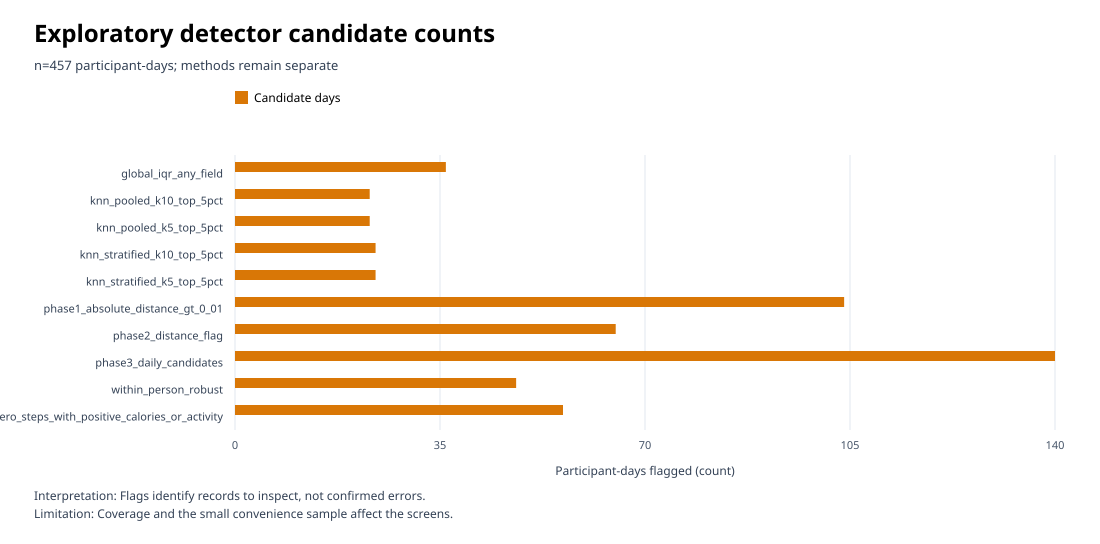

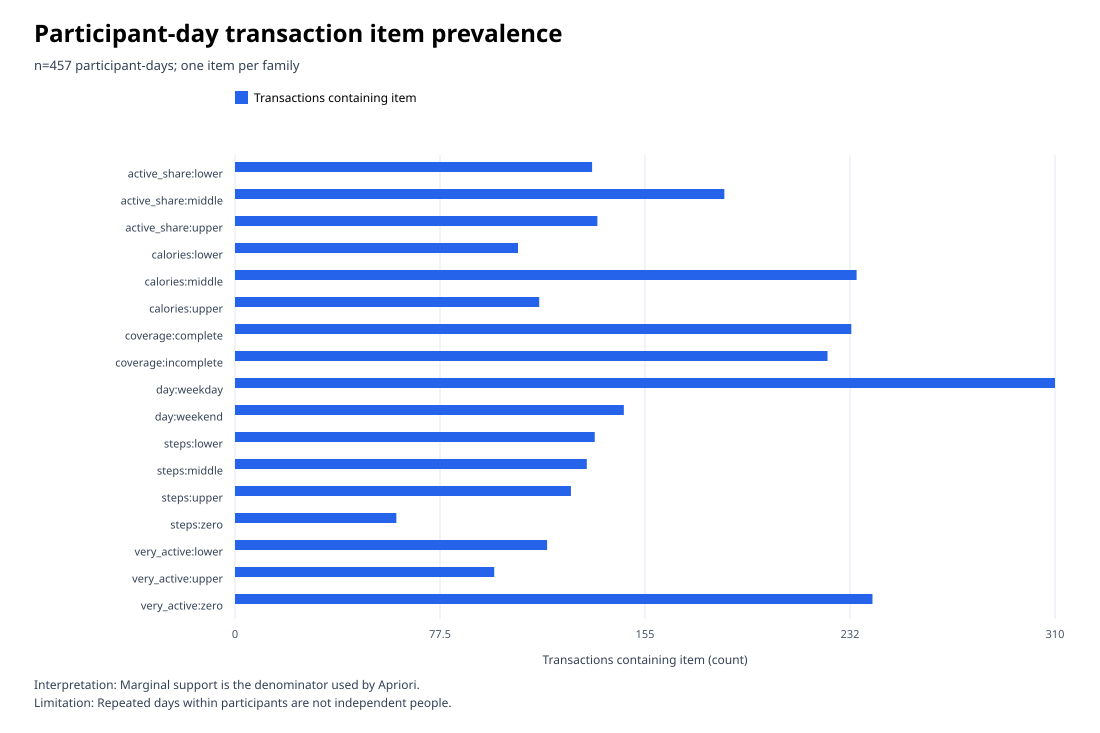

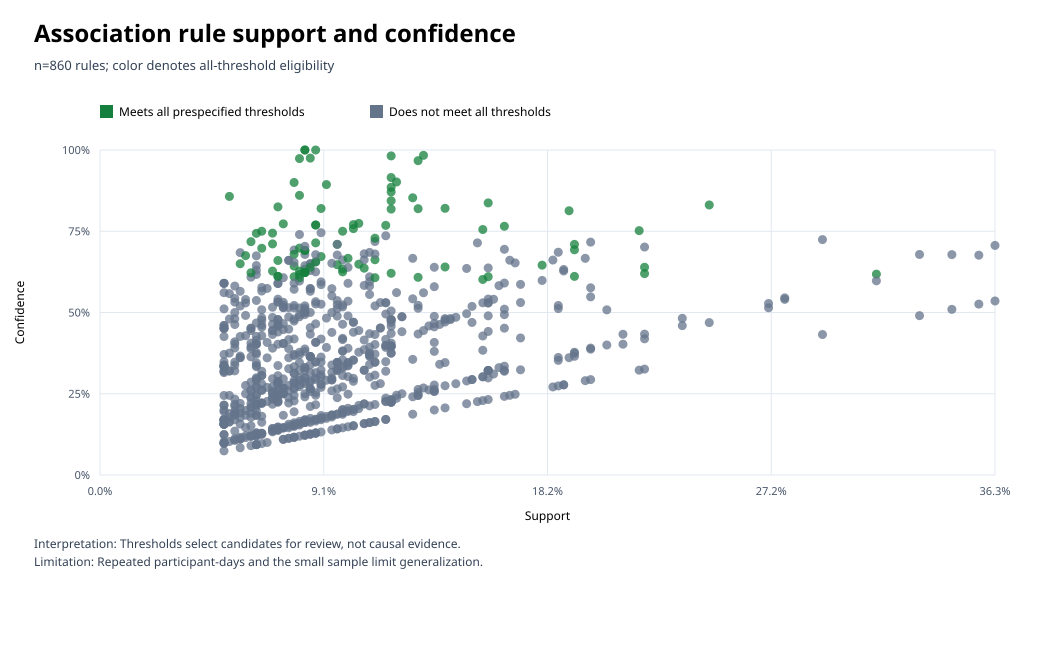

FITINSIGHT_PROOF | P5-NOTEBOOK-FIGURES | generated_from_computed_results=3 | SVG_XML=PASS


In [135]:
from collections import Counter
item_counts=Counter(item for transaction in association_result['transactions'] for item in transaction['items'])
item_labels=sorted(item_counts,key=lambda item:(association_result['family_by_item'][item],item))
write_horizontal_bars(assoc_out/'figures/01_transaction_item_prevalence.svg',title='Participant-day transaction item prevalence',description='Counts of transactions containing each prespecified category.',subtitle=f"n={len(association_result['transactions'])} participant-days; one item per family",labels=item_labels,series=[{'name':'Transactions containing item','color':PALETTE['blue'],'values':[item_counts[x] for x in item_labels]}],axis_label='Transactions containing item (count)',interpretation='Marginal support is the denominator used by Apriori.',limitation='Repeated days within participants are not independent people.')
rule_points=[{'x':r['support'],'y':r['confidence'],'eligible':r['eligible']} for r in association_result['rules']]
write_scatter(assoc_out/'figures/02_rule_support_confidence.svg',title='Association rule support and confidence',description='Each point is one directed rule.',subtitle=f"n={len(rule_points)} rules; color denotes all-threshold eligibility",points=rule_points,x_label='Support',y_label='Confidence',x_max=max((p['x'] for p in rule_points),default=.01),interpretation='Thresholds select candidates for review, not causal evidence.',limitation='Repeated participant-days and the small sample limit generalization.')
method_rows=anomaly_result['detector_counts']
write_horizontal_bars(anomaly_out/'figures/05_detector_candidate_counts.svg',title='Exploratory detector candidate counts',description='Candidate days identified by each anomaly screen.',subtitle=f"n={len(rows)} participant-days; methods remain separate",labels=[r['method'] for r in method_rows],series=[{'name':'Candidate days','color':PALETTE['orange'],'values':[r['candidate_days'] for r in method_rows]}],axis_label='Participant-days flagged (count)',interpretation='Flags identify records to inspect, not confirmed errors.',limitation='Coverage and the small convenience sample affect the screens.')
import xml.etree.ElementTree as ET
for path in sorted([assoc_out/'figures/01_transaction_item_prevalence.svg',assoc_out/'figures/02_rule_support_confidence.svg',anomaly_out/'figures/05_detector_candidate_counts.svg']):
    ET.parse(path);display(SVG(filename=str(path)))
print('FITINSIGHT_PROOF | P5-NOTEBOOK-FIGURES | generated_from_computed_results=3 | SVG_XML=PASS')

## Findings and limitations
Association thresholds and sensitivity outputs describe candidate patterns only. Participant-days are repeated observations within people. Daily and sleep episode candidates are separate grains; investigate them with coverage and source context.